# Thiết kế (Design) – 10 bước đánh giá hiệu năng
## Mô phỏng (DES) các cách làm bất đồng bộ: event loop, multi kernel thread, multi virtual thread

**Nhóm:** `<GroupName>`  **Thành viên:** `<tên – MSSV>`  **Hạn Phase 2:** 25/11/2026


**Hệ thống được mô hình hóa:** một request đi qua `Arrival → hàng đợi + trạm CPU → chờ I/O → Sink`. Sau khi xong CPU, request nhả ngay tài nguyên xử lý và chờ I/O ở trạm riêng (M/M/∞), nên chờ I/O không chiếm CPU.

| Mục | Nội dung |
|---|---|
| §0 | Yêu cầu cốt lõi, hệ thực và mô phỏng; chạy ví dụ asyncio; sample |
| §1–§7 | Bước 1–7 (chi tiết) |
| §8–§10 | Bước 8–10 (kế hoạch + mã hỗ trợ) |
| §11 | Mô tả module (kiến trúc, thành phần, luồng sự kiện) |
| §12 | Checklist và việc còn mở |
| §13 | Kế hoạch Phase 2 (development) |

In [1]:
import math, platform, sys, time
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Python", sys.version.split()[0], "|", platform.platform())

Python 3.12.3 | Linux-6.18.44-fc-v726-x86_64-with-glibc2.39


In [2]:
# Cấu hình đường dẫn tới framework BkitEvsim (thư mục chứa `bkitevsim/`).
# Cần bản `queues/ladder_queue.py` đã sửa (chỉ số bucket tuyệt đối); bản gốc dùng `% num_buckets` nên ô kiểm tra LadderQueue bên dưới báo lỗi.
import os, logging
CANDIDATES = [os.environ.get("BKITEVSIM_DIR", ""), "hk261_spe_BKsyspeEvsim", "../hk261_spe_BKsyspeEvsim"]
FRAMEWORK_DIR = next((p for p in CANDIDATES if p and os.path.isdir(os.path.join(p, "bkitevsim"))), None)
if FRAMEWORK_DIR is None:
    raise RuntimeError("Không thấy framework: giải nén hk261_spe_BKsyspeEvsim.zip cạnh notebook, "
                       "hoặc đặt biến môi trường BKITEVSIM_DIR trỏ tới thư mục chứa `bkitevsim/`.")
sys.path.insert(0, os.path.abspath(FRAMEWORK_DIR))
logging.disable(logging.CRITICAL)      # framework in cảnh báo "No events left" khi hết sự kiện; tắt cho gọn
print("Framework:", os.path.abspath(FRAMEWORK_DIR))

Framework: /home/claude/fw/hk261_spe_BKsyspeEvsim


In [3]:
# Kiểm tra thứ tự pop của LadderQueue: timestamp nhỏ hơn phải ra trước, kể cả khi cách nhau hơn num_buckets × bucket_width
from bkitevsim.core import Event
from bkitevsim.queues import LadderQueue
_q = LadderQueue(bucket_width=1.0)
for _t in (1030.0, 100.0):
    _q.push(Event(timestamp=_t, sender_id=0, receiver_id=0, event_type="X", payload={}))
assert [_q.pop().timestamp, _q.pop().timestamp] == [100.0, 1030.0], "LadderQueue pop sai thứ tự timestamp"
print("LadderQueue: thứ tự pop đúng")

LadderQueue: thứ tự pop đúng


## 0. Yêu cầu cốt lõi, hệ thực và mô phỏng

### 0.1 Yêu cầu của đề

Đề (đánh giá hiệu năng dựa trên hệ hàng đợi) yêu cầu **hai việc gắn với nhau**: (a) mô hình hóa bằng hệ hàng đợi trên DES, gồm sáu mô hình đơn (§2.1) và mạng hàng đợi (§2.2); (b) hệ thống có **giao tiếp/hoạt động bất đồng bộ không chặn** (§4–§5). Không chọn loại hàng đợi trước rồi áp vào hệ thống: nhóm xuất phát từ cách làm bất đồng bộ, chạy ví dụ asyncio, rồi đọc kết quả để thấy hàng đợi hình thành.

| Yêu cầu của đề | Nơi trả lời trong notebook |
|---|---|
| §2.1 Sáu mô hình hàng đợi đơn | §1.5, §6.1–§6.3; kiểm chứng ở §6.7 (E5) |
| §2.2 Mạng hàng đợi | CPU → I/O nối tiếp (§6.4, §6.8) |
| §2.3 Thiết kế tham chiếu (Arrival, Server, Processing event) | §11: `SourceLP`, `DispatcherLP`/`WorkerLP`, `IoLP`, `SinkLP` |
| §4 Giao tiếp không chặn | §1.4: server nhả ngay khi xong CPU, chờ I/O ở trạm riêng |
| §5.1 Năm thành phần của tác vụ bất đồng bộ | bảng bên dưới |
| §5.1 Verification và validation; tách thời gian mô phỏng khỏi thời gian thực | §6.7–§6.8, §9; ghi chú ở §6.6 |

### 0.2 Hai vai trò cần tách bạch

| | Hệ thực | Mô phỏng |
|---|---|---|
| Là gì | asyncio, JavaScript, Bun, Java Spring Loom | mô hình DES của các hệ thực, dựng bằng BkitEvsim |
| Mục đích | cách làm bất đồng bộ thật | quan sát hành vi của hệ thực ở nhiều mức tải và tham số |
| Việc của nhóm | chạy ví dụ, quan sát, hiểu cơ chế (§0.5) | thiết kế mô hình, cài đặt, chạy thí nghiệm, phân tích |

BkitEvsim được viết bằng asyncio chỉ là chuyện cài đặt của công cụ, không liên quan đến đối tượng nghiên cứu (giống viết trình biên dịch Go bằng Go).

### 0.3 Các cách làm bất đồng bộ

| Cách làm | Hệ thực | Khi chờ I/O | Biểu diễn trong DES |
|---|---|---|---|
| Event loop | Python asyncio, JavaScript (Node.js) | một luồng; chuyển sang tác vụ khác tại `await` hoặc callback; tác vụ CPU dài chặn cả vòng lặp | một đơn vị xử lý ($c = 1$), nhả khi chờ I/O |
| Multi kernel thread | Bun; Python bỏ GIL (từ 3.13) | nhiều thread của hệ điều hành chạy song song thật | $N$ đơn vị xử lý song song, mỗi thread nhả khi chờ I/O; mỗi thread một hàng riêng ($N \times$ M/M/1/K) |
| Multi virtual thread | Java Spring Loom | nhiều virtual thread trên ít carrier thread; chờ I/O thì nhả carrier | $c$ carrier thread dùng một hàng chung |

Đây là cách phân loại dùng trong thiết kế. Ở mức mô hình hóa hàng đợi của Phase 1, mỗi kernel thread của Bun là một trạm CPU M/M/1/K với hàng riêng, còn chờ I/O diễn ra ở trạm I/O chung; cách Bun phân việc cho các thread cần xác nhận khi cài đặt (§12).

### 0.4 Sample và vai trò

**Sample:** Repo GitHub: https://github.com/Frtrillo/spring-boot-virtual-threads-off-vs-on-vs-nodejs-typescript-benchmark
Bài Medium (cùng tác giả): https://medium.com/@fr.trillo7/java-vs-node-js-vs-bun-spring-boot-nestjs-9a84db4fe5aa

Bộ benchmark đo Java (Spring Boot), Node.js và Bun bằng `wrk` (8 thread, 1.000–2.000 kết nối, 60 s) trên bốn nhóm workload: tính toán thuần, tính toán ở mức framework, logic nghiệp vụ nặng CPU, I/O nặng đa core.

| # | Vai trò | Dùng ở bước |
|---|---|---|
| 1 | Thực tế để hiểu: cách đo web server bằng `wrk` | 1, 2, 7 |
| 2 | Kịch bản tải tham chiếu: closed-loop, 1.500 kết nối, 60 s | 7, 8 |
| 3 | Nguồn tham số **có giới hạn**: `μ` không lấy từ sample mà đặt theo kịch bản và phân tích độ nhạy (§4, §5) | 4 |

**Quy ước dùng sample**
- Sample chỉ cung cấp kịch bản tải và cấu trúc hệ thống; thời gian CPU `s` và độ trễ I/O `D` đặt theo kịch bản và quét độ nhạy.
- Mô hình không cố khớp từng con số của sample; mục đích là tìm điểm nghẽn và xem hệ nào bão hòa trước khi tải, `c`, `K`, `D`, `s` thay đổi.
- Thông lượng chỉ tính request hoàn thành; request bị từ chối đếm riêng và báo cáo cùng `P_block`.

### 0.5 Chạy trước các ví dụ asyncio (hệ thực)

Đây là **hệ thực**, chưa phải mô phỏng: chạy asyncio và thread thật rồi đọc kết quả. Phần A là các ví dụ của đề (Listing 1–3; Listing 2 được điền thân hàm). Phần B là ví dụ bổ sung của nhóm. Thời gian là giây thực nên dao động nhẹ giữa các lần chạy.

**A. Ví dụ trong đề**

In [4]:
import asyncio

# Listing 1 (đề): gather
async def process_event(event_id):
    await asyncio.sleep(0.1)                 # mô phỏng I/O bất đồng bộ
    return f"Event {event_id} processed"
async def main1():
    results = await asyncio.gather(process_event(1), process_event(2), process_event(3))
    print("Listing 1 gather       :", results)

# Listing 2 (đề, đã điền thân hàm): TaskGroup và as_completed
async def fetch_data(i):
    await asyncio.sleep(0.1 * i)
    return f"data{i}"
async def main2():
    async with asyncio.TaskGroup() as tg:
        task1 = tg.create_task(fetch_data(1))
        task2 = tg.create_task(fetch_data(2))
    print("Listing 2 TaskGroup    :", task1.result(), task2.result())
    order = [await r for r in asyncio.as_completed([fetch_data(3), fetch_data(1), fetch_data(2)])]
    print("Listing 2 as_completed :", order, "(thứ tự hoàn thành, gather thì theo thứ tự truyền vào)")

# Listing 3 (đề): Future
async def async_worker(future_obj):
    future_obj.set_result("Worker output")
async def main3():
    loop = asyncio.get_running_loop()
    my_future = loop.create_future()
    asyncio.create_task(async_worker(my_future))
    await my_future
    print("Listing 3 Future       :", my_future.result())

# Trong Jupyter dùng await trực tiếp; ngoài Jupyter dùng asyncio.run(main()). TaskGroup cần Python 3.11 trở lên.
await main1()
await main2()
await main3()

Listing 1 gather       : ['Event 1 processed', 'Event 2 processed', 'Event 3 processed']


Listing 2 TaskGroup    : data1 data2


Listing 2 as_completed : ['data1', 'data2', 'data3'] (thứ tự hoàn thành, gather thì theo thứ tự truyền vào)
Listing 3 Future       : Worker output


Kết quả cho thấy `gather` trả kết quả theo thứ tự truyền vào, còn `as_completed` trả theo thứ tự hoàn thành; `TaskGroup` chờ đủ các tác vụ con khi thoát khối; `Future` cho phép một coroutine chờ kết quả do nơi khác đặt sau. Đây là các thành phần ở §5.1 của đề.

**B. Ví dụ bổ sung của nhóm (event loop, blocking call, thread, StreamReader/StreamWriter)**

In [5]:
import asyncio, threading, time
from concurrent.futures import ThreadPoolExecutor

D_IO = 0.2                                   # thời gian chờ I/O của mỗi tác vụ (giây)
def tname(): return threading.current_thread().name
async def timed(fn):
    t0 = time.perf_counter(); r = await fn(); return time.perf_counter() - t0, r

# VD1  coroutine: await tuần tự và asyncio.gather (event loop một luồng)
async def io_task(i):
    await asyncio.sleep(D_IO)                # chờ I/O: nhường event loop cho tác vụ khác
    return tname()
async def ex1_seq():    return [await io_task(i) for i in range(3)]
async def ex1_gather(): return await asyncio.gather(*(io_task(i) for i in range(3)))

# VD2  lời gọi blocking đặt trong coroutine chặn cả event loop
async def blocking_task(i): time.sleep(D_IO)             # KHÔNG nhường event loop
async def ex2(): await asyncio.gather(*(blocking_task(i) for i in range(3)))

# VD3  nhiều kernel thread: lời gọi blocking chạy song song trên các thread
def blocking_job(i):
    time.sleep(D_IO); return tname()
def ex3(n_thread, n_job):
    t0 = time.perf_counter()
    with ThreadPoolExecutor(n_thread) as ex: names = list(ex.map(blocking_job, range(n_job)))
    return time.perf_counter() - t0, len(set(names))

# VD4  Future + callback
async def ex4():
    loop = asyncio.get_running_loop(); fut = loop.create_future(); log = []
    fut.add_done_callback(lambda f: log.append(f"callback nhận kết quả: {f.result()}"))
    loop.call_later(D_IO, fut.set_result, "dữ liệu sẵn sàng")
    log.append("đã đăng ký callback, tiếp tục chạy việc khác")
    await fut; await asyncio.sleep(0)
    return log

# VD5  StreamReader / StreamWriter: echo server trên localhost
async def ex5():
    async def handle(reader, writer):
        data = await reader.readline(); writer.write(data.upper()); await writer.drain(); writer.close()
    server = await asyncio.start_server(handle, "127.0.0.1", 0)
    port = server.sockets[0].getsockname()[1]
    reader, writer = await asyncio.open_connection("127.0.0.1", port)
    writer.write(b"xin chao\n"); await writer.drain()
    reply = await reader.readline(); writer.close(); await writer.wait_closed()
    server.close(); await server.wait_closed()
    return reply.decode().strip()

# Trong Jupyter dùng await trực tiếp; ngoài Jupyter bọc trong asyncio.run(main()).
t_seq, th1 = await timed(ex1_seq)
t_gat, th2 = await timed(ex1_gather)
t_blk, _   = await timed(ex2)
print(f"VD1 event loop, 3 tác vụ chờ I/O {D_IO}s")
print(f"    await tuần tự      : {t_seq:.2f} s")
print(f"    asyncio.gather     : {t_gat:.2f} s   (thread dùng: {sorted(set(th2))})")
print(f"VD2 3 lời gọi blocking trong coroutine: {t_blk:.2f} s   (event loop bị chặn, không chồng nhau)")
for n_thr in (1, 3, 6):
    t, used = ex3(n_thr, 6)
    print(f"VD3 kernel thread, 6 việc blocking, pool {n_thr} thread: {t:.2f} s   (số thread đã dùng: {used})")
print("VD4 Future + callback:")
for line in await ex4(): print("    -", line)
print("VD5 StreamReader/StreamWriter, server trả về:", await ex5())

VD1 event loop, 3 tác vụ chờ I/O 0.2s
    await tuần tự      : 0.60 s
    asyncio.gather     : 0.20 s   (thread dùng: ['MainThread'])
VD2 3 lời gọi blocking trong coroutine: 0.60 s   (event loop bị chặn, không chồng nhau)


VD3 kernel thread, 6 việc blocking, pool 1 thread: 1.20 s   (số thread đã dùng: 1)


VD3 kernel thread, 6 việc blocking, pool 3 thread: 0.40 s   (số thread đã dùng: 3)


VD3 kernel thread, 6 việc blocking, pool 6 thread: 0.20 s   (số thread đã dùng: 6)
VD4 Future + callback:
    - đã đăng ký callback, tiếp tục chạy việc khác
    - callback nhận kết quả: dữ liệu sẵn sàng


VD5 StreamReader/StreamWriter, server trả về: XIN CHAO


**Quan sát từ kết quả**

- **Event loop một luồng vẫn chồng được thời gian chờ I/O** (VD1): ba tác vụ chờ 0,2 s xong sau 0,2 s với `gather`, so với 0,6 s khi `await` tuần tự. Chỉ một thread (`MainThread`) làm cả ba. Đây là lý do mô hình cho chờ I/O không chiếm CPU.
- **Một lời gọi blocking chặn cả event loop** (VD2): ba lời gọi `time.sleep` trong coroutine mất 0,6 s vì không nhường vòng lặp. Khi tác vụ chiếm CPU lâu, các tác vụ còn lại **xếp hàng** chờ; đây là chỗ hàng đợi xuất hiện ở event loop.
- **Kernel thread chồng được blocking nhưng bị giới hạn bởi số thread** (VD3): 6 việc blocking mất 1,2 s với 1 thread, 0,4 s với 3 thread, 0,2 s với 6 thread. Việc dư thread **xếp hàng** chờ thread rảnh; đây là hàng đợi của cách làm đa luồng.
- **Callback và Future** (VD4) cho phép đăng ký việc xử lý rồi chạy tiếp; **StreamReader/StreamWriter** (VD5) là API mức cao của asyncio để đọc ghi mạng không chặn.
- Virtual thread (Loom) chạy trên Java nên không có ví dụ ở đây; được biểu diễn trong mô hình qua $c$ carrier thread (§0.3).

Các hàng đợi quan sát được (chờ vòng lặp, chờ thread) là cơ sở để chọn cách biểu diễn ở §1.4 và công cụ phân tích ở §1.5.

## 1. Bước 1 – Mục tiêu và ranh giới hệ thống

### 1.1 Mục tiêu

**Mục tiêu tổng quát:** đánh giá hiệu năng của ba cách làm bất đồng bộ khi một web server phục vụ nhiều request cùng lúc: **event loop** (asyncio, JavaScript/Node.js), **multi kernel thread** (Bun) và **multi virtual thread** (Java Spring Loom). Công cụ là mô phỏng sự kiện rời rạc (DES) trên BkitEvsim: dựng mô hình của từng cách làm, rồi quan sát độ trễ, thông lượng, hàng chờ và quá tải để xác định điểm nghẽn và mức tải mà hệ thống không còn đáp ứng được.

**Mục tiêu cụ thể**
- Dựng mô hình DES cho từng cách làm: request đến, được xử lý (CPU), chờ I/O (nhả tài nguyên xử lý để phục vụ request khác) rồi trả lời; sức chứa `K` ở trạm CPU.
- Ánh xạ từng cách làm sang mô hình DES (§0.3): event loop, multi kernel thread, multi virtual thread.
- Chạy trước các ví dụ asyncio (§0.5) để quan sát hành vi của hệ thực, làm cơ sở cho cách biểu diễn trong mô hình.
- Quan sát thời gian phản hồi, số request trong hệ thống, hiệu suất CPU và xác suất bị từ chối `P_block`.
- Quan sát hiện tượng quá tải, hàng chờ dài, request bị từ chối ở **ít nhất ba mức tải** (nhẹ, gần bão hòa, quá tải).
- Đánh giá hiệu năng toàn hệ thống (thông lượng, tỉ lệ bị từ chối, thời gian phản hồi) và xác định điểm nghẽn.
- Phân tích mức ảnh hưởng của các yếu tố (tải `γ`, số core `c`, dung lượng `K`, độ trễ I/O `D`, thời gian CPU `s`) lên hiệu năng.

### 1.2 Câu hỏi quan sát

1. Với cùng số core, hệ nào bão hòa trước khi tải tăng (event loop, kernel thread của Bun hay virtual thread của Loom)?
2. Với cùng tổng năng lực, cấu trúc hàng đợi nào cho `P_block` và `R` thấp hơn: một hàng chung cho `c` thread (Loom, M/M/c/K) hay mỗi thread một hàng riêng (Bun, $c\times$ M/M/1/K)?
3. Event loop một luồng bão hòa ở `1/s`; hệ nhiều luồng (kernel thread, virtual thread) ở `c/s`. Mô phỏng có tái hiện đúng các trần này không?
4. Giới hạn `K` và số core `c` ảnh hưởng `P_block` và `R` thế nào? Mở rộng `K` làm giảm `P_block` thật hay chỉ làm `R` dài hơn?
5. Thời gian chờ I/O `D` có làm tăng `R` cộng thêm đúng bằng `D` không, và có làm đổi thông lượng tối đa của hệ không (vì chờ I/O không chiếm CPU)?
6. Ở closed-loop khi `C > K`, tỉ lệ bị từ chối là bao nhiêu và `X·R` có bằng `C` không? Kết quả lệch nhiều nhất so với lý thuyết ở trạm nào và vì sao?
7. Hàng đợi nào hình thành khi chạy mô phỏng, và nó giải thích hành vi quan sát được (độ trễ tăng, bị từ chối) ra sao?

### 1.3 Ngưỡng tham chiếu (sẽ hiệu chỉnh khi chạy thử)

| Chỉ số | Ngưỡng | Ý nghĩa |
|---|---|---|
| `P_block,sys` | dưới 1% | hệ thống đủ tin cậy |
| `R` trung bình | dưới 100 ms (với `D` = 50 ms, nghĩa là chờ ở hàng CPU dưới 50 ms) | trải nghiệm chấp nhận được |
| `R` p99 | dưới 300 ms | độ trễ đuôi |
| `X` | `X ≥ 0,95·γ` | gần như mọi request đến đều được phục vụ |
| Chênh lệch mô phỏng và giải tích (node đơn) | dưới 5% | mô hình đúng |

### 1.4 Hệ thống và thông tin hỗ trợ

**Phạm vi:** từ lúc request đến server đến lúc phản hồi xong (hoặc bị từ chối). **Không xét:** mạng, TLS, database thật, nhiều node, garbage collection, thời gian khởi động runtime, retry của client (trừ closed-loop).

**Sơ đồ.**

```
                    bị từ chối khi số request ở trạm CPU = K (P_block)
                                          │
 Source(γ) ─► [ Trạm CPU: hàng chờ + c server, sức chứa K ] ─► [ Trạm I/O: chờ D, vô hạn chỗ ] ─► Sink
                  server nhả ngay sau khi xong CPU ──────────►   (chờ I/O không chiếm CPU)
```

**Khi request xong CPU:** server nhả ngay; request chờ I/O ở trạm riêng, không giới hạn chỗ (CPU: M/M/c/K → I/O: M/M/∞). Áp dụng cho event loop (asyncio, JavaScript/Node.js, $c = 1$), Bun ($N$ kernel thread, mỗi thread một hàng riêng) và Spring Loom (virtual thread, $c$ carrier thread).

**Hoạt động:** request đến theo quá trình Poisson (open-loop) hoặc do `C` kết nối sinh ra (closed-loop). Request đến khi trạm CPU đã đủ `K` request thì bị từ chối (không xếp hàng, không quay lại trong open-loop). Ngược lại request vào trạm CPU, chờ server rảnh, được xử lý trong `s` (trung bình), sau đó rời server và chờ I/O trong `D` (trung bình), rồi ra Sink.

**Các node (đơn vị thời gian: giây; giá trị khởi điểm, sẽ hiệu chỉnh khi chạy thử):**

| Node | Thành phần | Mô hình | c | K | μ |
|---|---|---|---|---|---|
| CPU | Event loop (asyncio, JavaScript/Node.js) | M/M/1/K | 1 | 100 | 1000/s (s = 1 ms) |
| CPU | Bun ($N = 8$ kernel thread, mỗi thread một hàng riêng; Phase 2) | $8 \times$ M/M/1/K | 1 mỗi hàng | 100 mỗi hàng | 1000/κ mỗi thread (κ = 1, thử 1,25 và 1,5) |
| CPU | Spring Loom (carrier thread) | M/M/c/K | 8 | 800 | 1000/s mỗi core |
| I/O | Trạm chờ I/O (cả ba cách làm) | M/M/∞ | ∞ | ∞ | 1/D = 20/s |
| Sink | Thu request hoàn thành | – | – | – | – |

**Giả định:**
1. Thời gian CPU phân phối mũ (để so với công thức); chạy thêm bản xác định để đo độ nhạy. Thời gian I/O mũ với trung bình `D` (giải tích) và bản xác định (độ nhạy).
2. Trạm I/O có số chỗ không giới hạn (hạ tầng backend không là nút cổ chai).
3. Bun được biểu diễn là $N$ kernel thread độc lập, mỗi thread một hàng chờ riêng; mỗi thread chỉ bị chiếm trong phần CPU rồi nhả và chờ I/O ở trạm I/O chung (cơ sở). Chi phí đồng bộ và chuyển ngữ cảnh của kernel thread đưa vào qua hệ số `κ` (`s` thành `κ·s`), còn Loom lấy `κ = 1`. Nếu Bun thực tế dùng một hàng chung thì cấu trúc trùng M/M/N/K như Loom.
4. `wrk`/nguồn tải không tranh CPU với server (LP độc lập).
5. Request bị từ chối ở cửa không được tính vào thông lượng thành công, đếm riêng.
6. Mỗi request chỉ chạy CPU **một lần** trước khi chờ I/O, không quay lại chiếm CPU sau khi xong I/O (không mô hình hóa callback/xử lý kết quả sau I/O).

**Chú thích – kernel thread của Bun và virtual thread của Loom.** Cả hai dùng 8 core nhưng khác cấu trúc hàng đợi. Với Bun (cơ sở), mỗi kernel thread có một hàng chờ riêng; tải được chia cho các thread trước khi vào hàng, nên một request không thể sang thread khác dù thread đó đang rảnh ⇒ **$8 \times$ M/M/1/K** (mỗi hàng nhận $\gamma/8$), trần thông lượng $N/(\kappa s)$ (8.000 req/s với $\kappa = 1$). **Spring Loom** có 8 carrier thread cùng lấy việc từ **một hàng chờ chung** ⇒ **M/M/8/K**, trần $c/s$. Cùng tổng năng lực $8/s$ nhưng M/M/8/K gộp hàng nên $W_q$ và $P_{\text{block}}$ thường thấp hơn. Bảng node dùng event loop một luồng ($c = 1$) làm cấu hình cơ sở; Bun là kịch bản Phase 2.

### 1.5 Mô hình hàng đợi

Sáu mô hình hàng đợi đơn ở đề (§2.1) là khung mô hình hóa bắt buộc của bài. Thiết kế đi từ cách làm bất đồng bộ (§0.3) rồi biểu diễn bằng các mô hình này; công thức giải tích dùng để kiểm chứng mô phỏng và để giải thích hàng đợi quan sát được ở §0.5.

**Hàng đợi đơn (ký hiệu Kendall $A/S/c/K$).** $A$ = phân phối khoảng cách đến (M = mũ, tương đương Poisson), $S$ = phân phối thời gian phục vụ (M = mũ, trung bình $1/\mu$), $c$ = số server, $K$ = sức chứa (đang phục vụ + đang chờ; khách đến khi đủ $K$ thì bị từ chối; $K=\infty$ không giới hạn). Mặc định FCFS và nguồn vô hạn.

**Quá trình sinh tử.** Gọi $n$ là số request trong node. $n$ tăng 1 với tốc độ $\lambda$ (khi $n<K$), giảm 1 với tốc độ $\min(n,c)\,\mu$. Ở trạng thái dừng, với $a=\lambda/\mu$ và $\rho=\lambda/(c\mu)$, xác suất có $n$ request trong node là $\pi_n$:

$$\tilde p_n=\begin{cases}\dfrac{a^n}{n!}, & 0\le n\le c\\[2mm]\dfrac{a^c}{c!}\Big(\dfrac{a}{c}\Big)^{n-c}, & c<n\le K\end{cases}\qquad \pi_n=\frac{\tilde p_n}{\sum_{k=0}^{K}\tilde p_k}$$

Xác suất bị từ chối là $P_{\mathrm{block}}=\pi_K$ (PASTA: request Poisson thấy trạng thái trung bình theo thời gian).

Sáu mô hình của đề (§2.1) là trường hợp riêng, chỉ khác cặp $(c,K)$ (M/M/n/n của đề là M/M/c/c ở đây):

| Mô hình | $(c, K)$ | Dùng để phân tích | Điều kiện / công thức chính |
|---|---|---|---|
| M/M/1 | $(1,\infty)$ | trạm CPU của event loop khi bỏ giới hạn $K$ | $\pi_n=(1-\rho)\rho^{n}$, $\rho<1$ |
| M/M/c | $(c,\infty)$ | trạm CPU của Loom khi bỏ giới hạn $K$ | Erlang C: $C_E(c,a)=\dfrac{\frac{a^c}{c!}\frac{1}{1-\rho}}{\sum_{k=0}^{c-1}\frac{a^k}{k!}+\frac{a^c}{c!}\frac{1}{1-\rho}}$, $\rho<1$ |
| M/M/∞ | $(\infty,\infty)$ | **trạm chờ I/O** | $\pi_n=e^{-a}\,\dfrac{a^{n}}{n!}$ |
| M/M/1/K | $(1,K)$ | **trạm CPU của event loop (và mỗi thread của Bun)** | $\pi_K=\dfrac{(1-\rho)\rho^{K}}{1-\rho^{K+1}}$ ($\rho\ne1$); $\pi_K=\dfrac{1}{K+1}$ ($\rho=1$) |
| M/M/c/K | $(c,K)$ | **trạm CPU của Loom** | $\pi_K=\dfrac{\tilde p_K}{\sum_{k=0}^{K}\tilde p_k}$ |
| M/M/c/c | $(c,c)$ | giới hạn kết nối backend không có chỗ chờ (mở rộng, §7.4 S8) | Erlang B: $B(c,a)=\dfrac{a^{c}/c!}{\sum_{j=0}^{c}a^{j}/j!}$ |

**Định luật Little.** $L=\lambda_{\mathrm{eff}}W$ và $L_q=\lambda_{\mathrm{eff}}W_q$, với $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$ là tốc độ request thực sự được nhận. Đúng cho mọi kiểu hàng đợi nên dùng để kiểm tra mô phỏng.

**Tandem CPU → I/O.** Trạm I/O là M/M/∞ nên không bao giờ làm trạm CPU chậm lại: hai trạm **tách rời** về thời gian. Khi đó các chỉ số trung bình tính chính xác từ hai công thức đơn:
- tốc độ vào trạm I/O: $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$ (luồng ra của trạm CPU hữu hạn không còn Poisson, nhưng số request trung bình trong trạm M/M/∞ chỉ phụ thuộc $\lambda_{\mathrm{eff}}$ và $D$);
- $R=W_{\mathrm{CPU}}+D$, $\quad L_{\mathrm{IO}}=\lambda_{\mathrm{eff}}\,D$, $\quad L_{\mathrm{sys}}=L_{\mathrm{CPU}}+\lambda_{\mathrm{eff}}\,D$.

Vì tính chính xác này, công thức giải tích dùng để **kiểm chứng mô phỏng** (sai số chỉ do nhiễu lấy mẫu); các phân vị (p95, p99) của $R$ chỉ có xấp xỉ.

**Phương trình lưu lượng.** Đường đi tuyến tính: $\lambda_{\mathrm{CPU}}=\gamma$, $\ \lambda_{\mathrm{IO}}=\gamma\,(1-\pi_K)$. Không có vòng phản hồi trong open-loop; trong closed-loop $\gamma$ do $C$ kết nối quyết định ($\gamma\approx X_{\mathrm{ok}}+X_{\mathrm{err}}$, với $X_{\mathrm{err}}$ là tốc độ bị từ chối).

**Điểm nghẽn lý thuyết** (thông lượng tối đa $X_{\max}$):

$$X_{\max}=\frac{c}{s}$$

Thông lượng tối đa chỉ phụ thuộc CPU (event loop $c=1$: $1/s$; Bun: $N/(\kappa s)$; Loom: $c/s$) và không phụ thuộc `D`, vì chờ I/O không chiếm CPU.


## 2. Bước 2 – Dịch vụ và kết quả

**Dịch vụ:** server nhận một request, xử lý CPU (trung bình `s = 1/μ`), chờ I/O (trung bình `D`, **không chiếm CPU**), rồi trả lời.

| Kết quả của một request | Định nghĩa trong mô phỏng | Ghi nhận |
|---|---|---|
| Hoàn thành | đi hết Source → CPU → I/O → Sink | thông lượng, thời gian phản hồi |
| Bị từ chối | đến khi trạm CPU đã đủ `K` request | bộ đếm từ chối, `P_block` |
| Timeout (mở rộng) | thời gian phản hồi vượt ngưỡng | đếm riêng, không tính vào thông lượng thành công |
| Đang dở khi kết thúc mô phỏng | chưa xong lúc $T_{\mathrm{end}}$ | không đưa vào trung bình (right-censoring) |

Quy ước: **thông lượng chỉ tính request hoàn thành thành công**; request bị từ chối đếm riêng và báo cáo cùng `P_block`.

**Ba mốc thời gian của một lần chạy** (đều là thời gian mô phỏng, $T_{\mathrm{warm}} \le T_{\mathrm{stop}} \le T_{\mathrm{end}}$):

| Mốc | Ký hiệu | Định nghĩa |
|---|---|---|
| Hết khởi động | $T_{\mathrm{warm}}$ | bắt đầu ghi thống kê (sau 10% request đầu) |
| Dừng sinh request mới | $T_{\mathrm{stop}}$ | thời điểm đến của request cuối cùng (đủ $N_{\mathrm{req}}$); sau đó Source không sinh request mới (closed-loop: các kết nối ngừng gửi) |
| Kết thúc mô phỏng | $T_{\mathrm{end}}$ | hàng đợi sự kiện rỗng hoặc đạt `end_time`; request còn dở lúc này bị right-censoring |

Cửa sổ quan sát $T_{\mathrm{obs}}=T_{\mathrm{stop}}-T_{\mathrm{warm}}$ là mẫu số của mọi tốc độ ($X$, $\lambda_{\mathrm{eff}}$) và của các trung bình theo thời gian ($U$, $L$). Request đến trong $[T_{\mathrm{warm}},T_{\mathrm{stop}}]$ được theo dõi đến khi xong (có thể sau $T_{\mathrm{stop}}$, trước $T_{\mathrm{end}}$). Đoạn $(T_{\mathrm{stop}},T_{\mathrm{end}}]$ chỉ là giai đoạn xả hàng, **không** tính vào $T_{\mathrm{obs}}$ vì tải giảm dần làm thấp $X$.

**Kết quả thu được:** bảng chỉ số từng trạm và toàn hệ thống, đối chiếu mô phỏng với giải tích, biểu đồ chỉ số theo tải, điểm nghẽn.

## 3. Bước 3 – Metric

Chia thành bốn nhóm: chỉ số trạm CPU, chỉ số trạm I/O, chỉ số toàn hệ thống, chỉ số độ tin cậy của kết quả.

**Quy ước chung**
- Chỉ tính sau khởi động, trong cửa sổ quan sát $[T_{\mathrm{warm}},T_{\mathrm{stop}}]$ với $T_{\mathrm{obs}}=T_{\mathrm{stop}}-T_{\mathrm{warm}}$ (§2).
- Chỉ số theo trạm chỉ tính request được trạm nhận; request bị từ chối chỉ xuất hiện trong $P_{\mathrm{block}}$.
- Ký hiệu: $a=\lambda/\mu$, $\rho=\lambda/(c\mu)$; $\pi_n$ là xác suất trạng thái dừng (§1.5).

### 3.1 Trạm CPU

| Metric | Ký hiệu | Công thức đo (mô phỏng) | Công thức lý thuyết | Ý nghĩa |
|---|---|---|---|---|
| Tốc độ vào hiệu dụng | $\lambda_{\mathrm{eff}}$ | số request được nhận $/\,T_{\mathrm{obs}}$ | $\lambda(1-\pi_K)$ | đầu vào của Little và $U$; dùng $\lambda$ thay $\lambda_{\mathrm{eff}}$ là sai khi có từ chối |
| Hiệu suất CPU | $U$ | $\int(\text{server bận})\,dt\,/\,(c\,T_{\mathrm{obs}})$ | $\lambda_{\mathrm{eff}}/(c\mu)$ | nút nào cần theo dõi; không đủ để kết luận nút cổ chai khi $K$ hữu hạn |
| Số request trong trạm | $L_{\mathrm{CPU}}$ | trung bình theo thời gian của $N(t)$ | $\sum_{n}n\,\pi_n$ | mức đông đúc |
| Số request chờ | $L_q$ | như trên, chỉ đếm hàng chờ | $\sum_{n>c}(n-c)\,\pi_n$ | |
| Thời gian chờ | $W_q$ | trung bình (bắt đầu CPU − đến) | $L_q/\lambda_{\mathrm{eff}}$ | so với ngưỡng |
| Thời gian ở trạm CPU | $W_{\mathrm{CPU}}$ | trung bình (xong CPU − đến) | $L_{\mathrm{CPU}}/\lambda_{\mathrm{eff}}$ | gồm chờ + CPU |
| Độ lệch chuẩn, p95, p99 | – | từ mẫu đã sắp xếp | dạng đóng chỉ cho M/M/1 và M/M/c: $P(W_q>t)=C_E(c,a)\,e^{-(c\mu-\lambda)t}$ | trung bình che giấu độ trễ đuôi |
| Xác suất bị từ chối | $P_{\mathrm{block}}$ | số bị từ chối / số đến | $\pi_K$ | **metric chính** |

### 3.2 Trạm I/O

| Metric | Ký hiệu | Công thức đo | Công thức lý thuyết | Ý nghĩa |
|---|---|---|---|---|
| Số request đang chờ I/O | $L_{\mathrm{IO}}$ | trung bình theo thời gian | $\lambda_{\mathrm{eff}}\,D$ | số kết nối backend đồng thời cần có |
| Thời gian ở trạm I/O | $W_{\mathrm{IO}}$ | trung bình (Sink − xong CPU) | $D$ | kiểm tra trực tiếp trạm M/M/∞ |

### 3.3 Toàn hệ thống

| Metric | Ký hiệu | Công thức đo | Ý nghĩa |
|---|---|---|---|
| Thông lượng thành công | $X$ | request hoàn thành $/\,T_{\mathrm{obs}}$ | hiệu quả thực tế; luôn $X\le\gamma$ |
| Thời gian phản hồi | $R$ | trung bình (Sink − đến), báo cả p95/p99; lý thuyết $W_{\mathrm{CPU}}+D$ | trải nghiệm người dùng |
| Xác suất bị từ chối toàn hệ thống | $P_{\mathrm{block,sys}}$ | bị từ chối / đến | độ tin cậy; so với ngưỡng 1% |
| Số request trong hệ thống | $L_{\mathrm{sys}}$ | trung bình $N_{\mathrm{CPU}}+N_{\mathrm{IO}}$ | $=X\,R$ theo Little |
| Hiệu suất sản xuất | $\eta=X/\gamma$ | thành công / đến | so với ngưỡng 95% |
| Điểm nghẽn và ngưỡng tải | $X_{\max}$ | $c/s$ | trả lời "hệ nào bão hòa trước" |

Trong closed-loop thêm **tỉ lệ lỗi** = bị từ chối / (bị từ chối + thành công).

### 3.4 Độ tin cậy của kết quả

Mỗi metric cho một giá trị $x_k$ ở mỗi lần chạy $k=1,\dots,m$ (mỗi lần một seed).
- **Khoảng tin cậy 95% (t-Student):** $\bar x \pm t_{0.975,\,m-1}\,\dfrac{\hat\sigma}{\sqrt m}$, với $\hat\sigma$ là độ lệch chuẩn mẫu của $x_1,\dots,x_m$. Các mẫu trong cùng một lần chạy tương quan nên **không** coi từng request là mẫu độc lập.
- **Sai số tương đối so với lý thuyết:** $\delta_{\mathrm{rel}}=\dfrac{|x_{\mathrm{sim}}-x_{\mathrm{theory}}|}{x_{\mathrm{theory}}}$; khớp khi khoảng tin cậy chứa giá trị lý thuyết. Mọi chỉ số trung bình đều có nghiệm chính xác.
- **Kiểm tra Little:** $\dfrac{|L_{\mathrm{CPU}}-\lambda_{\mathrm{eff}}W_{\mathrm{CPU}}|}{L_{\mathrm{CPU}}}$ và $\dfrac{|L_{\mathrm{IO}}-\lambda_{\mathrm{eff}}D|}{L_{\mathrm{IO}}}$; toàn hệ thống $\dfrac{|L_{\mathrm{sys}}-XR|}{L_{\mathrm{sys}}}$; closed-loop kiểm tra $X_{\mathrm{ok}}R_{\mathrm{ok}}+X_{\mathrm{err}}R_{\mathrm{err}}\approx C$ (tính cả chu kỳ lỗi, §7.1).
- **Bảo toàn request:** $N_0+N_{\mathrm{arrived}}=N_{\mathrm{done}}+N_{\mathrm{rejected}}+N_{\mathrm{remaining}}$, với $N_0$ là số request đang có trong hệ lúc bắt đầu quan sát ($T_{\mathrm{warm}}$).


## 4. Bước 4 – Tham số

Tên tham số trong thiết kế (khớp tên tham số của `Dispatcher`/LP trong BkitEvsim):

| Tham số | Ý nghĩa | Công thức / giá trị |
|---|---|---|
| `mean_interarrival_time` | thời gian đến trung bình ở nguồn | `1/γ` |
| `mean_servicetime` | thời gian CPU trung bình của một server | `s = 1/μ` |
| `maxServer` | số server của trạm CPU | `c` |
| `maxSystemSize` | sức chứa trạm CPU | `K` |
| `mean_io_time` | thời gian I/O trung bình (trạm I/O vô hạn chỗ) | `D` |
| `reject_time` | thời gian xử lý một phản hồi từ chối; closed-loop: kết nối chờ khoảng này trước khi gửi request kế tiếp | $t_{\mathrm{err}} = 10$ ms (đã chạy thử: với $0{,}1$ ms các lần bị từ chối dùng hết $N_{\mathrm{req}}$ trong vài ms mô phỏng nên cửa sổ đo không còn ý nghĩa) |

Lưu ý: $t_{\mathrm{err}}$ phải **dương**. Nếu bằng 0, khi trạm đầy kết nối bị từ chối sẽ gửi lại ngay tại cùng thời điểm mô phỏng, tạo vòng lặp vô hạn không tiến thời gian và làm $X_{\mathrm{err}}R_{\mathrm{err}}=0$ trong kiểm tra Little. Open-loop không dùng tham số này.


In [6]:
params = pd.DataFrame([
    ["Mô phỏng", "Framework",                    "BkitEvsim (công cụ DES), coroutine LP",         "chạy từ thư mục gốc framework"],
    ["Mô phỏng", "Phân phối đến",                "Poisson (open-loop) / C kết nối, think time z = 0 (closed-loop)", "γ = tốc độ đến"],
    ["Mô phỏng", "Phân phối phục vụ CPU",        "mũ (kiểm chứng giải tích) / xác định (độ nhạy)", "chạy cả hai và nêu sai khác"],
    ["Mô phỏng", "Phân phối thời gian I/O",      "mũ trung bình D (giải tích) / xác định D (độ nhạy)", ""],
    ["Mô phỏng", "Số request mỗi lần chạy",      "30.000 (BkitEvsim)", "bỏ 10% đầu (warm-up)"],
    ["Mô phỏng", "Số lần lặp m",                 "m = 10 hạt giống (đề xuất); 30 nếu đủ thời gian", "t(0,975; m−1) = 2,262 khi m = 10"],
    ["Mô phỏng", "bucket_width của LadderQueue", "T_end/900", "chỉ ảnh hưởng tốc độ; chỉ số bucket tuyệt đối, không phụ thuộc số bucket"],
    ["Mô phỏng", "Dispatcher",                   "sequential, distributed_sequential",          "kỳ vọng hai loại cho kết quả tương đương"],
    ["Kịch bản", "Thời gian CPU mỗi request s", "0,2 / 1 / 5 ms",                              "đặt theo kịch bản, không lấy từ sample"],
    ["Kịch bản", "Độ trễ I/O D",                "10 / 50 / 200 ms",                            ""],
    ["Kịch bản", "Số core / carrier thread c",  "1, 4, 8",                                     "event loop: 1; Bun: N thread"],
    ["Kịch bản", "Dung lượng K = q·c (q: chỗ mỗi core)", "q = 10 / 100 / ∞",                       "K gồm đang chạy + hàng chờ"],
    ["Kịch bản", "Thời gian từ chối reject_time (t_err)", "t_err = 10 ms",          "closed-loop: thời gian trước khi kết nối gửi lại sau khi bị từ chối; t_err = 0 gây vòng lặp vô hạn, t_err = 0,1 ms làm cửa sổ đo quá ngắn khi C > K"],
    ["Kịch bản", "Số kết nối C (closed-loop)",   "100, 1.500, 5.000",                          "1.500 kết nối (lớn hơn K)"],
    ["Kịch bản", "Hệ số chi phí CPU của kernel thread κ", "1 / 1,25 / 1,5", "giả thuyết (chi phí đồng bộ, chuyển ngữ cảnh), không lấy từ sample"],
], columns=["Nhóm", "Tham số", "Giá trị", "Ghi chú"])
params

,Nhóm,Tham số,Giá trị,Ghi chú
0,Mô phỏng,Framework,"BkitEvsim (công cụ DES), coroutine LP",chạy từ thư mục gốc framework
1,Mô phỏng,Phân phối đến,"Poisson (open-loop) / C kết nối, think time z = 0 (closed-loop)",γ = tốc độ đến
2,Mô phỏng,Phân phối phục vụ CPU,mũ (kiểm chứng giải tích) / xác định (độ nhạy),chạy cả hai và nêu sai khác
3,Mô phỏng,Phân phối thời gian I/O,mũ trung bình D (giải tích) / xác định D (độ nhạy),
4,Mô phỏng,Số request mỗi lần chạy,30.000 (BkitEvsim),bỏ 10% đầu (warm-up)
5,Mô phỏng,Số lần lặp m,m = 10 hạt giống (đề xuất); 30 nếu đủ thời gian,"t(0,975; m−1) = 2,262 khi m = 10"
6,Mô phỏng,bucket_width của LadderQueue,T_end/900,"chỉ ảnh hưởng tốc độ; chỉ số bucket tuyệt đối, không phụ thuộc số bucket"
7,Mô phỏng,Dispatcher,"sequential, distributed_sequential",kỳ vọng hai loại cho kết quả tương đương
8,Kịch bản,Thời gian CPU mỗi request s,"0,2 / 1 / 5 ms","đặt theo kịch bản, không lấy từ sample"
9,Kịch bản,Độ trễ I/O D,10 / 50 / 200 ms,


**Phân loại hằng số, tham số, biến.**

| Loại | Nội dung |
|---|---|
| Hằng số | thời gian khởi động (10% số request đầu); số lần lặp $m$; phân phối CPU và I/O (mũ ở bản chính) |
| Tham số (đầu vào của một lần chạy) | `mean_interarrival_time = 1/γ`, `mean_servicetime = s`, `maxServer = c`, `maxSystemSize = K`, `mean_io_time = D`, `reject_time` $=t_{\mathrm{err}}$, seed |
| Biến yếu tố (đổi giữa kịch bản) | `γ` (trực tiếp; hoặc qua `ρ_ref` khi khảo sát nội bộ một hệ, §5), `c`, `K`, `D`, `s`, `κ`, `C` |
| Biến trạng thái | `N_CPU(t)`, số server bận, $N_{\mathrm{IO}}(t)$, độ dài hàng chờ |
| Biến đầu ra | các metric ở §3 (ba chỉ số chính: `P_block,sys`, `R`, `X`) |



## 5. Bước 5 – Factor nghiên cứu

Mức in đậm là mức cơ sở.

In [7]:
factors = {
    "hệ thống":            ["**Event loop (c=1)**", "Bun (N=8 kernel thread, hàng riêng; Phase 2)", "**Spring Loom (c=8)**"],
    "mô hình tải":         ["**open-loop** (γ = ρ_ref · trần)", "closed-loop (C kết nối)"],
    "tải: ρ_ref (nội bộ 1 hệ) / γ tuyệt đối (so nhiều hệ)": ["0,3", "0,7", "**0,95**", "1,1"],
    "độ trễ I/O D":        ["10 ms", "**50 ms**", "200 ms"],
    "thời gian CPU s":     ["0,2 ms", "**1 ms**", "5 ms"],
    "số core c":           [1, 4, "**8**"],
    "dung lượng q = K/c": ["10", "**100**", "∞"],
}
pd.DataFrame([(k, len(v), ", ".join(map(str, v))) for k, v in factors.items()],
             columns=["Factor", "Số mức", "Các mức"])

,Factor,Số mức,Các mức
0,hệ thống,3,"**Event loop (c=1)**, Bun (N=8 kernel thread, hàng riêng; Phase 2), **Spring Loom (c=8)**"
1,mô hình tải,2,"**open-loop** (γ = ρ_ref · trần), closed-loop (C kết nối)"
2,tải: ρ_ref (nội bộ 1 hệ) / γ tuyệt đối (so nhiều hệ),4,"0,3, 0,7, **0,95**, 1,1"
3,độ trễ I/O D,3,"10 ms, **50 ms**, 200 ms"
4,thời gian CPU s,3,"0,2 ms, **1 ms**, 5 ms"
5,số core c,3,"1, 4, **8**"
6,dung lượng q = K/c,3,"10, **100**, ∞"


| Factor | Giả thuyết ảnh hưởng (kiểm chứng ở Phase 2) | Chỉ số phản hồi chính |
|---|---|---|
| hệ thống | cùng số core, chênh lệch chủ yếu do `μ` và cấu trúc hàng đợi (một hàng chung hay mỗi thread một hàng) | `X`, `R`, `P_block` |
| tải `ρ_ref` | `P_block` và `R` tăng phi tuyến khi tiến gần trần | `P_block`, `R`, `X` |
| `D` | `R` tăng đúng `D`; `D` không đổi trần thông lượng vì chờ I/O không chiếm CPU | `R`, `X` |
| `s` | `s` lớn làm CPU là nút cổ chai, event loop bão hòa ở `1/s` | `X`, `W_q` |
| `c` | event loop một luồng không tăng tốc theo core; Loom tăng theo `c/s` | `X`, `U` |
| `K` | `K` nhỏ làm `P_block` tăng khi tải gần bão hòa; `K` lớn kéo dài `R` | `P_block`, `R` |
| `κ` (kernel thread, Bun) | `κ` lớn kéo trần thông lượng của Bun xuống `N/(κ·s)` | `X` |
| `C` (closed-loop) | `C > K` làm tỉ lệ lỗi cao | tỉ lệ lỗi, `X·R` |

**Quy tắc chọn mức tải.**
- **Khảo sát nội bộ một hệ thống** (đổi $K$, $c$, $D$, $s$, ... trên cùng một hệ): dùng tải tương đối $\rho_{\mathrm{ref}}=\gamma/X_{\max}$, vì khi đó $X_{\max}$ cố định và $\rho_{\mathrm{ref}}$ chỉ là cách đặt lại thang tải.
- **So sánh nhiều hệ thống** (E1, E3: Event loop, Loom; Bun ở Phase 2): **không** dùng $\rho_{\mathrm{ref}}$ chung, vì mỗi hệ có $X_{\max}$ khác nhau ($1/s$, $c/s$), nên cùng $\rho_{\mathrm{ref}}$ nghĩa là các hệ nhận tải khác nhau và so sánh bị lệch. Phải dùng **tải tuyệt đối $\gamma$ (req/s)** giống nhau cho mọi hệ. Ở E1, $\gamma$ lấy từ một danh sách chung phủ cả vùng bão hòa của event loop và của Loom. Ở E3, mỗi cặp $(D, s)$ dùng $\gamma = 0{,}8/s$ (0,8 lần trần của hệ yếu nhất) cho mọi hệ.


## 6. Bước 6 – Kỹ thuật đánh giá

| Kỹ thuật | Nhận xét | Sử dụng |
|---|---|---|
| Mô hình giải tích | có công thức đóng cho từng node và cho tandem CPU → I/O (chỉ số trung bình) | **mốc đối chiếu** |
| Mô phỏng sự kiện rời rạc (DES) trên BkitEvsim | xử lý được hàng chờ hữu hạn, nhiều trạm, request bị từ chối; đổi tham số dễ; chạy lặp để có khoảng tin cậy | **kỹ thuật chính** (thuật toán §6.5, mã §6.6) |
| Chạy hệ thực | chạy được ví dụ asyncio (§0.5); Bun, Spring Loom chưa đo | **bổ trợ**: quan sát hành vi hệ thực để xác định cách biểu diễn và đối chiếu xu hướng; nếu cài được, chạy một server nhỏ cho Bun/Spring Loom để ước lượng `s`, `D` |

### 6.1 Ánh xạ cách làm bất đồng bộ sang mô hình DES

| Hệ thống | Trạm CPU | Trạm I/O | Ghi chú |
|---|---|---|---|
| Event loop (asyncio, Node.js) | M/M/1/K | M/M/∞ | Xong CPU là nhả luồng ngay |
| Spring + Loom (c carrier thread) | M/M/c/K | M/M/∞ | Xong CPU là nhả carrier ngay |
| Bun (multi kernel thread, Phase 2) | $8 \times$ M/M/1/K, μ/κ | M/M/∞ | Xong CPU là nhả thread ngay; mỗi thread một hàng riêng |

Đủ sáu mô hình của đề (§2.1): M/M/1 và M/M/c (khi $K=\infty$), M/M/1/K (event loop, mỗi thread của Bun), M/M/c/K (Loom), M/M/∞ (trạm I/O), M/M/c/c (giới hạn kết nối backend, kịch bản mở rộng S8).

### 6.2 Cài đặt công thức giải tích (cho node đơn)

Hàm bên dưới cài đặt các công thức của §1.5 (tóm tắt ở §6.3). Ký hiệu trong mã: `erlang_c` là $C_E(c,a)$, `erlang_b` là $B(c,a)$, `mmck` tính $\pi_n$ trong không gian log.

In [8]:
def mm1(lam, mu):
    rho = lam / mu
    if rho >= 1:
        return dict(rho=rho, stable=False, L=np.inf, W=np.inf, Wq=np.inf)
    W = 1 / (mu - lam)
    return dict(rho=rho, stable=True, L=rho / (1 - rho), W=W, Wq=W - 1 / mu)


def erlang_c(c, a):
    rho = a / c
    if rho >= 1:
        return 1.0
    s = sum(a**k / math.factorial(k) for k in range(c))
    top = a**c / math.factorial(c) / (1 - rho)
    return top / (s + top)


def mmc(lam, mu, c):
    a = lam / mu; rho = a / c
    if rho >= 1:
        return dict(rho=rho, stable=False, Pwait=1.0, L=np.inf, W=np.inf, Wq=np.inf)
    pw = erlang_c(c, a); Wq = pw / (c * mu - lam); W = Wq + 1 / mu
    return dict(rho=rho, stable=True, Pwait=pw, L=lam * W, W=W, Wq=Wq)


def mminf(lam, mu):
    return dict(L=lam / mu, W=1 / mu, Wq=0.0)


def mmck(lam, mu, c, K):
    """M/M/c/K (K>=c) tinh trong khong gian log de on dinh voi c, K lon."""
    a = lam / mu
    lp = []
    for n in range(K + 1):
        if n <= c:
            lp.append(n * math.log(a) - math.lgamma(n + 1) if a > 0 else (0.0 if n == 0 else -math.inf))
        else:
            lp.append(n * math.log(a) - math.lgamma(c + 1) - (n - c) * math.log(c))
    m = max(lp)
    p = [math.exp(x - m) for x in lp]
    Z = sum(p); p = [x / Z for x in p]
    pK = p[K]
    L = sum(n * p[n] for n in range(K + 1))
    Lq = sum((n - c) * p[n] for n in range(c + 1, K + 1))
    lam_eff = lam * (1 - pK)
    W = L / lam_eff if lam_eff > 0 else 0.0
    return dict(Pblock=pK, lam_eff=lam_eff, L=L, Lq=Lq, W=W, Wq=Lq / lam_eff if lam_eff > 0 else 0.0,
                U=lam_eff / (c * mu), P0=p[0])


def erlang_b(c, a):
    """Erlang B: B(c, a) cho M/M/c/c."""
    B = 1.0
    for k in range(1, c + 1):
        B = a * B / (k + a * B)
    return B


assert abs(mm1(8, 10)["W"] - 0.5) < 1e-12
assert abs(mmck(5, 10, 1, 1)["Pblock"] - 5 / 15) < 1e-12
assert abs(erlang_b(2, 1.0) - 0.2) < 1e-12
assert abs(mmck(30, 10, 5, 5)["Pblock"] - erlang_b(5, 3.0)) < 1e-12
print("Công thức qua kiểm tra cơ bản")

Công thức qua kiểm tra cơ bản


### 6.3 Tóm tắt công thức cài đặt trong mã

Với $a=\lambda/\mu$, $\rho=\lambda/(c\mu)$, $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$ (chi tiết ở §1.5):

| Mô hình | Công thức |
|---|---|
| M/M/1 ($\rho<1$) | $W=\dfrac{1}{\mu-\lambda}$, $\ W_q=W-\dfrac1\mu$, $\ L=\dfrac{\rho}{1-\rho}$ |
| M/M/c ($\rho<1$) | $W_q=\dfrac{C_E(c,a)}{c\mu-\lambda}$, $\ W=W_q+\dfrac1\mu$, $\ L=\lambda W$ |
| M/M/∞ | $L=a$, $\ W=\dfrac1\mu$, $\ W_q=0$ |
| M/M/c/K (gồm M/M/1/K khi $c=1$) | $P_{\mathrm{block}}=\pi_K$, $\ L=\sum_{n=0}^{K}n\,\pi_n$, $\ L_q=\sum_{n=c+1}^{K}(n-c)\,\pi_n$, $\ W=\dfrac{L}{\lambda_{\mathrm{eff}}}$, $\ W_q=\dfrac{L_q}{\lambda_{\mathrm{eff}}}$, $\ U=\dfrac{\lambda_{\mathrm{eff}}}{c\mu}$ |
| M/M/c/c | $P_{\mathrm{block}}=B(c,a)=\dfrac{a^{c}/c!}{\sum_{j=0}^{c}a^{j}/j!}$; trùng M/M/c/K với $K=c$ (kiểm tra ở ô mã trên) |


### 6.4 Công thức giải tích cho tandem CPU → I/O

Trạm I/O là M/M/∞ không phản hồi lên trạm CPU nên, với $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$:

$$R=W_{\mathrm{CPU}}+D,\qquad L_{\mathrm{IO}}=\lambda_{\mathrm{eff}}\,D,\qquad L_{\mathrm{sys}}=L_{\mathrm{CPU}}+\lambda_{\mathrm{eff}}\,D,\qquad X=\lambda_{\mathrm{eff}}$$

(§1.5). Các giá trị này là **chính xác** cho các chỉ số trung bình.


In [9]:
def tandem(lam, c, K, s, D):
    """Giai tich cho he CPU -> I/O: tram CPU M/M/c/K -> tram I/O M/M/inf (khong phan hoi len CPU),
    nen cac chi so trung binh tinh chinh xac: R = W_A + D, L_B = lam_eff * D."""
    A = mmck(lam, 1.0 / s, c, K)
    return dict(Pblock=A["Pblock"], X=A["lam_eff"], W_A=A["W"], Wq=A["Wq"], R=A["W"] + D, L_A=A["L"],
                L_B=A["lam_eff"] * D, L_sys=A["L"] + A["lam_eff"] * D, U=A["U"])

### 6.5 Thuật toán mô phỏng

Phần này ghi trực tiếp thuật toán của mô hình ở §1.4, ở hai mức: **(A)** thuật toán hướng sự kiện lõi, độc lập framework; **(B)** cách chia thành các LP trên BkitEvsim (mã chạy được ở §6.6).

**Trạng thái và thống kê**
- `now`: thời gian mô phỏng; `n_cpu`: số request trong trạm CPU (đang chạy + đang chờ core); `busy`: số core bận; `Q`: hàng chờ core (FIFO); `n_io`: số request đang chờ I/O.
- Bộ đếm: `arrived`, `rejected`, `done` (chỉ đếm sau warm-up); danh sách `R[]` thời gian phản hồi.
- Tích phân theo thời gian (sau warm-up): `∫n_cpu dt`, `∫n_io dt`, `∫busy dt`.

**(A) Thuật toán lõi (hướng sự kiện)**

```
INPUT:  γ, c, K, s, D, t_err, T_warm, N_req, seed
INIT:   rng ← Random(seed);  now ← 0;  n_cpu ← busy ← n_io ← 0;  Q ← ∅
        FEL ← hàng đợi ưu tiên theo timestamp (LadderQueue)
        FEL.push(ARRIVAL, Exp(γ))                       # closed-loop: đẩy C sự kiện ARRIVAL tại t = 0

WHILE FEL ≠ ∅:
    e ← FEL.pop_min();  Δ ← e.t − now;  now ← e.t
    cộng ∫n_cpu, ∫n_io, ∫busy phần của [now−Δ, now] nằm trong [T_warm, T_stop]

    CASE e.type OF
      ARRIVAL:
        IF đã sinh = N_req:  BỎ QUA                    # không sinh request mới sau T_stop
        đã sinh++;  T_stop ← now                       # T_stop = thời điểm đến của request thứ N_req
        open-loop: FEL.push(ARRIVAL, now + Exp(γ))
        req ← request mới (t_arr = now)
        IF n_cpu = K:  TỪ_CHỐI(req)                    # trạm CPU đầy: từ chối ở cửa
        ELSE:          VÀO_CPU(req)

      CPU_DONE(req):                                   # xong phục vụ CPU
        busy−−;  n_cpu−−                               # nhả core ngay
        n_io++;  FEL.push(IO_DONE(req), now + Exp(D))
        IF Q ≠ ∅:  busy++;  BẮT_ĐẦU(Q.pop())

      IO_DONE(req):
        n_io−−;  GHI_PHẢN_HỒI(req)

VÀO_CPU(req):    n_cpu++;  IF busy < c:  busy++;  BẮT_ĐẦU(req)   ELSE:  Q.push(req)
BẮT_ĐẦU(req):    FEL.push(CPU_DONE(req), now + Exp(s))
TỪ_CHỐI(req):    IF req.t_arr ≥ T_warm:  rejected++
                 closed-loop: FEL.push(ARRIVAL, now + t_err)               # t_err = reject_time > 0
GHI_PHẢN_HỒI(req): IF req.t_arr ≥ T_warm:  R.append(now − req.t_arr);  done++
                   closed-loop: FEL.push(ARRIVAL, now + z)                 # z = 0 (think time)

OUTPUT: P_block = rejected / arrived;  X = done / T_obs;  R̄, p95, p99 từ R[]
        L_cpu = ∫n_cpu / T_obs;  L_io = ∫n_io / T_obs;  U = ∫busy / (c·T_obs)
        với T_obs = T_stop − T_warm
```

**(B) Cài đặt trên BkitEvsim **

Mỗi thành phần là một lớp con của `BkSysCoLogicalProcess`. Theo mẫu của framework, **toàn bộ xử lý nằm trong `handle_event`** (kiểu PDES cổ điển); `coroutine_run` chỉ lên lịch sự kiện đầu tiên. LP gửi sự kiện bằng `send_event(Event(timestamp, sender_id, receiver_id, event_type, payload))`. Thời gian phục vụ CPU và độ trễ I/O được thể hiện bằng cách **gửi sự kiện cho chính mình với timestamp ở tương lai** (`SERVED`, `IO_FIN`), nên không cần `await advance_time` và không bị giới hạn một server mỗi LP chờ một lúc; mỗi server vẫn là một `WorkerLP` riêng (c server = c LP).

```
SourceLP:      coroutine_run:  gửi ARRIVAL (tới chính nó) tại Exp(γ)        # closed-loop: C ARRIVAL tại t = 0
               ON ARRIVAL:     nếu đã sinh < N_req:  gửi ARRIVAL kế tiếp tại now + Exp(γ);  gửi REQ{rid, t_arr} → DISP
               ON NEXT:        (closed-loop) sinh request kế tiếp ngay

DispatcherLP:  idle ← [0 … c−1];  Q ← ∅;  n ← 0                              # ghi lại (t, n, busy) mỗi lần đổi
               ON REQ:   nếu n = K:  gửi REJECT → SINK
                         ngược lại:  n++;  nếu idle ≠ ∅: gửi JOB → worker rảnh   ngược lại: Q.push
               ON IDLE{w}: n−−;  nếu Q ≠ ∅: gửi JOB(Q.pop) → worker w   ngược lại: idle.push(w)

WorkerLP[w]:   ON JOB:     gửi SERVED (tới chính nó) tại now + Exp(s)
               ON SERVED:  gửi IO_REQ → IO   (D = 0: gửi DONE → SINK, dùng ở §6.7)
                           gửi IDLE{w} → DISP                                  # nhả server ngay

IoLP (M/M/∞):  ON IO_REQ:  n_io++;  gửi IO_FIN (tới chính nó) tại now + Exp(D)   # không giới hạn số request đồng thời
               ON IO_FIN:  n_io−−;  gửi DONE → SINK

SinkLP:        ON DONE:    R.append(now − t_arr);  closed-loop: gửi NEXT → SRC tại now
               ON REJECT:  rejected++;             closed-loop: gửi NEXT → SRC tại now + t_err   # t_err = reject_time > 0
```

**Thu thập thống kê, kết thúc, tái lập**
- **Warm-up:** bỏ mọi thống kê trước `T_warm` (10% request đầu); các tích phân chỉ cộng từ `T_warm`.
- **Kết thúc:** Source dừng sinh request mới tại $T_{stop}$ (đủ `N_req`); mô phỏng kết thúc tại $T_{end}$ khi hàng đợi sự kiện rỗng hoặc `now ≥ end_time`; request còn dở lúc kết thúc không đưa vào trung bình (right-censoring). `T_obs = T_stop − T_warm` (không tính đoạn xả hàng sau `T_stop`) để tránh đuôi xả hàng làm thấp `X`.
- **Tái lập:** mỗi LP dùng bộ sinh số ngẫu nhiên riêng với seed `base_seed + lp_id`; cùng seed thì kết quả giống hệt.
- **Chi phí:** thuật toán lõi (A) sinh khoảng **3 sự kiện mỗi request** (`ARRIVAL`, `CPU_DONE`, `IO_DONE`). Bản cài đặt tách LP trên BkitEvsim (B) sinh khoảng **8 sự kiện mỗi request** (`ARRIVAL`, `REQ`, `JOB`, `SERVED`, `IO_REQ`, `IDLE`, `IO_FIN`, `DONE`), vì mỗi bước đi qua một LP khác phải gửi sự kiện riêng. Request bị từ chối chỉ sinh khoảng 3 sự kiện (`ARRIVAL`, `REQ`, `REJECT`). Tổng chi phí tỉ lệ với `N_req` (mỗi thao tác hàng đợi ưu tiên khoảng O(1) với LadderQueue).

**Lưu ý khi cài đặt**
- Tham số `timeout` của `wait_for`/`wait_for_multiple` tính theo **giây đồng hồ thật**, trái với yêu cầu tách thời gian mô phỏng khỏi thời gian thực. Mã ở §6.6 không dùng `wait_for`; mọi độ trễ là sự kiện có timestamp mô phỏng. Timeout của request (kịch bản mở rộng) mô hình bằng sự kiện `TIMEOUT` tại `now + τ`.
- Không dựa vào thứ tự xử lý của các sự kiện có **cùng timestamp** (ví dụ `REQ` và `IDLE` đến cùng lúc). Kiểm tra: hai dispatcher `sequential` và `distributed_sequential` cho kết quả giống hệt nhau với cùng seed (§6.8).
- **LadderQueue:** bản framework dùng trong bài đã sửa `_get_bucket_index` thành chỉ số bucket tuyệt đối `floor(timestamp / bucket_width)` (bản gốc dùng `% num_buckets`, nên hai timestamp cách nhau quá `num_buckets × bucket_width` bị gộp vào cùng bucket và có thể pop sai thứ tự). Nhờ đó thứ tự pop luôn trùng thứ tự timestamp; ô kiểm tra ở đầu notebook xác nhận điều này. `bucket_width` chỉ ảnh hưởng tốc độ; `run_model` đặt `bucket_width = T_end / 900`.
- Framework **không có sẵn thống kê hàng đợi**; mã ghi lại `(t, n_cpu, busy)` và `(t, n_io)` mỗi lần đổi trạng thái rồi tính trung bình theo thời gian sau mô phỏng.
- `end_time` phải lớn hơn thời điểm request cuối xong; `run_model` đặt `T_end = 3·N_req/γ + 50(s+D)`; closed-loop dùng `T_end = 3·N_req·max((s+D)/C, s/c) + 50(s+D)` (vì $X \le \min(C/(s+D),\,c/s)$), tránh `T_end` quá lớn làm `bucket_width = T_end/900` thô so với khoảng cách giữa các sự kiện.

### 6.6 Mã mô hình trên BkitEvsim

Mô hình gồm `SourceLP`, `DispatcherLP`, `WorkerLP × c`, `IoLP`, `SinkLP`. Hàm `run_model(γ, c, K, s, D)` dựng `Simulation`, tạo LP, chạy và tính các chỉ số (sau warm-up 10%): `P_block`, `X`, `R`, p95, p99, `L_cpu`, `U`, $L_{\mathrm{IO}}$. Với `D = 0` mô hình chỉ còn một trạm M/M/c/K, dùng để kiểm chứng node đơn (§6.7).

In [10]:
import random
from collections import deque
from bkitevsim.core import Event, BkSysLogicalProcessState, Simulation, SimulationOptions
from bkitevsim.core.logical_coProcess import BkSysCoLogicalProcess

SRC, DISP, IO, SINK, W0 = 0, 1, 2, 3, 10          # lp_id cua Source, Dispatcher, Io, Sink; worker k co id W0 + k


class _Base(BkSysCoLogicalProcess):
    def __init__(self, lp_id, seed=1, **kw):
        super().__init__(lp_id, BkSysLogicalProcessState(), lookahead=0.0)
        self.rng = random.Random(seed * 1000 + lp_id)

    def _send(self, now, dst, etype, payload=None, at=None):
        self.send_event(Event(timestamp=now if at is None else at, sender_id=self.lp_id, receiver_id=dst,
                              event_type=etype, payload=payload or {}))

    async def coroutine_run(self):                  # moi viec xu ly nam o handle_event
        return


class SourceLP(_Base):
    def __init__(self, lp_id, seed=1, gamma=1.0, n_req=1000, closed_C=0, **kw):
        super().__init__(lp_id, seed)
        self.gamma, self.n_req, self.C = gamma, n_req, closed_C
        self.sent = 0; self.t_last = 0.0

    async def coroutine_run(self):
        if self.C:                                  # closed-loop: C ket noi gui request tai t = 0
            for _ in range(self.C): self._send(0.0, self.lp_id, "ARRIVAL", {}, at=0.0)
        else:                                       # open-loop: Poisson(gamma)
            self._send(0.0, self.lp_id, "ARRIVAL", {}, at=self.rng.expovariate(self.gamma))

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "ARRIVAL" or e.event_type == "NEXT":
            if self.sent >= self.n_req: return
            self.sent += 1; self.t_last = t
            if not self.C and e.event_type == "ARRIVAL":
                self._send(t, self.lp_id, "ARRIVAL", {}, at=t + self.rng.expovariate(self.gamma))
            self._send(t, DISP, "REQ", {"rid": self.sent, "t_arr": t})


class DispatcherLP(_Base):
    def __init__(self, lp_id, seed=1, c=1, K=10**9, **kw):
        super().__init__(lp_id, seed)
        self.K, self.idle, self.Q, self.n = K, list(range(c)), deque(), 0
        self.c = c; self.trace = [(0.0, 0, 0)]     # (t, n_cpu, busy)

    def _log(self, t): self.trace.append((t, self.n, self.c - len(self.idle)))

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "REQ":
            if self.n >= self.K:
                self._send(t, SINK, "REJECT", e.payload)
            else:
                self.n += 1
                if self.idle: self._send(t, W0 + self.idle.pop(), "JOB", e.payload)
                else: self.Q.append(e.payload)
                self._log(t)
        elif e.event_type == "IDLE":
            self.n -= 1; w = e.payload["w"]
            if self.Q: self._send(t, W0 + w, "JOB", self.Q.popleft())
            else: self.idle.append(w)
            self._log(t)


class WorkerLP(_Base):
    def __init__(self, lp_id, seed=1, s=1e-3, D=0.0, **kw):
        super().__init__(lp_id, seed)
        self.s, self.D = s, D

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "JOB":
            dur = self.rng.expovariate(1 / self.s)
            self._send(t, self.lp_id, "SERVED", e.payload, at=t + dur)
        elif e.event_type == "SERVED":
            if self.D > 0: self._send(t, IO, "IO_REQ", e.payload)
            else: self._send(t, SINK, "DONE", e.payload)      # D = 0: tra loi ngay (kiem chung node don)
            self._send(t, DISP, "IDLE", {"w": self.lp_id - W0})


class IoLP(_Base):                                   # M/M/inf: khong gioi han so request dong thoi
    def __init__(self, lp_id, seed=1, D=0.05, **kw):
        super().__init__(lp_id, seed)
        self.D = D; self.n = 0; self.trace = [(0.0, 0)]

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "IO_REQ":
            self.n += 1; self.trace.append((t, self.n))
            self._send(t, self.lp_id, "IO_FIN", e.payload, at=t + self.rng.expovariate(1 / self.D))
        elif e.event_type == "IO_FIN":
            self.n -= 1; self.trace.append((t, self.n))
            self._send(t, SINK, "DONE", e.payload)


class SinkLP(_Base):
    def __init__(self, lp_id, seed=1, closed=False, t_err=1e-4, **kw):
        super().__init__(lp_id, seed)
        self.closed, self.t_err = closed, t_err
        self.resp = []; self.rejected = []; self.done_t = []

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "DONE":
            self.resp.append((e.payload["t_arr"], t - e.payload["t_arr"])); self.done_t.append(t)
            if self.closed: self._send(t, SRC, "NEXT", {})
        elif e.event_type == "REJECT":
            self.rejected.append(e.payload["t_arr"])
            # closed-loop: ket noi gui lai sau t_err > 0 (t_err = 0 se lap vo han tai cung timestamp)
            if self.closed: self._send(t, SRC, "NEXT", {}, at=t + self.t_err)


MODELS = {"SourceLP": SourceLP, "DispatcherLP": DispatcherLP, "WorkerLP": WorkerLP, "IoLP": IoLP, "SinkLP": SinkLP}


import concurrent.futures


def _run_sim(sim):
    # Jupyter da co san event loop, con framework goi asyncio.run() nen phai chay sim.run() trong thread rieng.
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as ex:
        return ex.submit(sim.run).result()


def run_model(gamma, c, K, s, D, n_req=20000, warm=0.1, seed=1, closed_C=0, dispatcher="sequential", t_err=1e-2):
    # Dung Simulation cua BkitEvsim, chay va tinh cac chi so sau warm-up.
    import numpy as np
    if closed_C:   # closed-loop: X <= min(C/(s+D), c/s) nen n_req request can khong qua n_req * max((s+D)/C, s/c) giay
        t_end = 3 * n_req * max((s + D) / closed_C, s / c) + 50 * (s + D)
    else:
        t_end = (n_req / gamma) * 3 + 50 * (s + D)
    sim = Simulation(SimulationOptions(end_time=t_end, dispatcher=dispatcher, bucket_width=max(t_end / 900, 1e-3)),
                     models=MODELS)
    sim.create_lp(SRC, "SourceLP", seed=seed, gamma=gamma, n_req=n_req, closed_C=closed_C)
    sim.create_lp(DISP, "DispatcherLP", seed=seed, c=c, K=K)
    if D > 0: sim.create_lp(IO, "IoLP", seed=seed, D=D)
    sim.create_lp(SINK, "SinkLP", seed=seed, closed=bool(closed_C), t_err=t_err)
    for k in range(c): sim.create_lp(W0 + k, "WorkerLP", seed=seed, s=s, D=D)
    stats = _run_sim(sim)
    src, disp, sink = sim.get_lp(SRC), sim.get_lp(DISP), sim.get_lp(SINK)
    io = sim.get_lp(IO) if D > 0 else None
    t_warm = warm * src.t_last; t_stop = src.t_last; T = t_stop - t_warm
    def tavg(trace, col):                               # trung binh theo thoi gian tren [t_warm, t_stop]
        a = np.array(trace, dtype=float); t = a[:, 0]; v = a[:, col]
        t1 = np.minimum(np.append(t[1:], t_stop), t_stop); t0 = np.maximum(t, t_warm)
        return float(np.sum(v * np.clip(t1 - t0, 0, None)) / T)
    resp = np.array([r for ta, r in sink.resp if ta >= t_warm]); rej = [ta for ta in sink.rejected if ta >= t_warm]
    n_obs = len(resp) + len(rej)
    nan = float("nan"); has = len(resp) > 0            # cua so do co the khong co request hoan thanh (closed-loop, C >> K)
    return dict(Pblock=len(rej) / n_obs if n_obs else nan, X=len(resp) / T, R=float(resp.mean()) if has else nan,
                p95=float(np.percentile(resp, 95)) if has else nan, p99=float(np.percentile(resp, 99)) if has else nan,
                L_cpu=tavg(disp.trace, 1), U=tavg(disp.trace, 2) / c,
                L_io=tavg(io.trace, 1) if io else float("nan"), events=stats["events_processed"],
                wall=stats["wall_time"], n_done=len(resp), n_rej=len(rej))

### 6.7 Kiểm chứng từng node đơn trên framework

Mỗi mô hình hàng đợi được chạy bằng `run_model(..., D=0)` (một trạm M/M/c/K, `K` rất lớn nếu hàng chờ vô hạn) với 30.000 request, lặp 5 hạt giống và so với công thức ở §6.3 (khoảng tin cậy 95% theo phân phối t). M/M/∞ (trạm I/O) được kiểm chứng ở cột $L_{\mathrm{IO}}$ của §6.8.

In [11]:
BIG = 10**9
cases = [
    ("M/M/1",               7, 10, 1,  BIG, lambda: mm1(7, 10)["W"]),
    ("M/M/1/K (K=5)",       9, 10, 1,  5,   lambda: mmck(9, 10, 1, 5)["W"]),
    ("M/M/c (c=4)",        32, 10, 4,  BIG, lambda: mmc(32, 10, 4)["W"]),
    ("M/M/c/K (c=4,K=10)", 38, 10, 4,  10,  lambda: mmck(38, 10, 4, 10)["W"]),
    ("M/M/c/c (c=5)",      30, 10, 5,  5,   lambda: mmck(30, 10, 5, 5)["W"]),
]
rows = []
for name, lam, mu, c, K, f in cases:
    runs_ = [run_model(lam, c, K, 1 / mu, 0.0, n_req=30_000, seed=sd) for sd in range(1, 6)]     # 5 hạt giống
    w = np.array([r["R"] for r in runs_]); pb = np.mean([r["Pblock"] for r in runs_])
    h = stats.sem(w) * stats.t.ppf(0.975, len(w) - 1)
    W_th = f(); pb_th = mmck(lam, mu, c, K)["Pblock"] if K < BIG else 0.0
    rows.append([name, W_th * 1000, w.mean() * 1000, (w.mean() - h) * 1000, (w.mean() + h) * 1000,
                 100 * (w.mean() - W_th) / W_th, bool((w.mean() - h) <= W_th <= (w.mean() + h)), pb_th, pb])
verif = pd.DataFrame(rows, columns=["Mô hình", "W giải tích (ms)", "W BkitEvsim TB (ms)", "CI95 dưới", "CI95 trên",
                                    "Sai số W (%)", "CI chứa giá trị lý thuyết", "P_block giải tích", "P_block BkitEvsim"])
print("Sai số W lớn nhất (%):", round(float(verif["Sai số W (%)"].abs().max()), 2),
      "| giá trị lý thuyết nằm trong CI95 ở mọi mô hình:", bool(verif["CI chứa giá trị lý thuyết"].all()))
verif.round(4)

Sai số W lớn nhất (%): 2.48 | giá trị lý thuyết nằm trong CI95 ở mọi mô hình: True


,Mô hình,W giải tích (ms),W BkitEvsim TB (ms),CI95 dưới,CI95 trên,Sai số W (%),CI chứa giá trị lý thuyết,P_block giải tích,P_block BkitEvsim
0,M/M/1,333.3333,341.3360,324.9234,357.7486,2.4008,True,0.0000,0.0000
1,M/M/1/K (K=5),279.0286,281.5162,276.3074,286.7250,0.8915,True,0.1260,0.1287
2,M/M/c (c=4),174.5541,178.8835,166.1332,191.6338,2.4803,True,0.0000,0.0000
3,"M/M/c/K (c=4,K=10)",157.3815,157.8945,154.4632,161.3258,0.3260,True,0.0868,0.0892
4,M/M/c/c (c=5),100.0000,100.1344,99.1169,101.1518,0.1344,True,0.1101,0.1107


### 6.8 Kiểm chứng tandem CPU → I/O, hai dispatcher và tính tái lập

In [12]:
s, D = 1e-3, 50e-3
rows = []
for c, K, rho in [(1, 100, 0.7), (1, 100, 0.95), (1, 100, 1.1), (1, 10, 0.95), (8, 800, 0.95), (8, 800, 1.1)]:
    lam = rho * c / s
    th = tandem(lam, c, K, s, D)
    sm = run_model(lam, c, K, s, D, n_req=30_000, seed=3)
    rows.append([f"c={c}, K={K}, ρ={rho}", th["Pblock"], sm["Pblock"], th["R"] * 1e3, sm["R"] * 1e3,
                 100 * (sm["R"] - th["R"]) / th["R"], th["L_B"], sm["L_io"], th["L_A"], sm["L_cpu"]])
chk = pd.DataFrame(rows, columns=["Cấu hình", "P_block th", "P_block sim", "R th (ms)", "R sim (ms)", "sai số R (%)",
                                  "L_I/O th", "L_I/O sim", "L_CPU th", "L_CPU sim"])
chk.round(4)

# Kiểm chứng tái lập và hai dispatcher: cùng seed thì kết quả giống hệt
a = run_model(3000, 8, 800, s, D, n_req=10_000, seed=123)
b = run_model(3000, 8, 800, s, D, n_req=10_000, seed=123)
d = run_model(3000, 8, 800, s, D, n_req=10_000, seed=123, dispatcher="distributed_sequential")
keys = ["Pblock", "X", "R", "p95", "p99", "L_cpu", "U", "L_io"]
assert all(a[k] == b[k] for k in keys), "Lỗi tái lập seed!"
assert all(a[k] == d[k] for k in keys), "sequential và distributed_sequential cho kết quả khác nhau!"
print("Kiểm chứng tái lập seed: PASS | sequential = distributed_sequential: PASS")


Kiểm chứng tái lập seed: PASS | sequential = distributed_sequential: PASS


In [13]:
# Closed-loop: kiểm tra Little  X_ok·R_ok + X_err·t_err ≈ C  (t_err = 10 ms; n_req đủ lớn để cửa sổ đo dài)
rows = []
for name, c_, K_, C_, n_ in [("Event loop", 1, 100, 100, 30_000), ("Event loop", 1, 100, 1500, 150_000), ("Loom", 8, 800, 1500, 150_000)]:
    r = run_model(0, c_, K_, s, D, n_req=n_, closed_C=C_, seed=1, t_err=1e-2)
    T_obs = r["n_done"] / r["X"]; x_err = r["n_rej"] / T_obs
    rows.append([f"{name}, C={C_}, K={K_}", r["Pblock"], r["X"], r["R"] * 1e3, r["X"] * r["R"] + x_err * 1e-2, C_])
cl = pd.DataFrame(rows, columns=["Cấu hình", "P_block", "X ok (req/s)", "R ok (ms)", "X·R + X_err·t_err", "C"])
cl["lệch so với C (%)"] = 100 * (cl["X·R + X_err·t_err"] - cl["C"]) / cl["C"]
assert (cl["lệch so với C (%)"].abs() < 5).all(), "Little closed-loop lệch quá 5%"
cl.round(3)

,Cấu hình,P_block,X ok (req/s),R ok (ms),X·R + X_err·t_err,C,lệch so với C (%)
0,"Event loop, C=100, K=100",0.000,996.544,100.404,100.058,100,0.058
1,"Event loop, C=1500, K=100",0.993,979.613,152.752,1512.604,1500,0.840
2,"Loom, C=1500, K=800",0.788,8066.245,148.748,1499.816,1500,-0.012


## 7. Bước 7 – Workload

Workload trong mô phỏng là **chuỗi request đến server**, định nghĩa bởi mô hình tải, mức tải và kịch bản dịch vụ. Cấu hình hệ thống giữ nguyên trong một workload.

### 7.1 Mô hình tải
- **Open-loop:** tốc độ đến `γ` cố định (Poisson), không phụ thuộc phản hồi. Dùng để so với công thức M/M/· và đo độ trễ đuôi.
- **Closed-loop:** `C` kết nối đồng thời, mỗi kết nối gửi request kế tiếp ngay khi nhận phản hồi (think time `z = 0`), kể cả phản hồi bị từ chối. Đây là cách `wrk` của sample hoạt động. Kiểm tra Little cho closed-loop: $$X_{\mathrm{ok}}R_{\mathrm{ok}}+X_{\mathrm{err}}R_{\mathrm{err}}\approx C,\qquad R_{\mathrm{err}}=t_{\mathrm{err}}>0$$ (mỗi kết nối luôn ở trong một request thành công hoặc một chu kỳ bị từ chối). Vì $R_{\mathrm{err}}=t_{\mathrm{err}}>0$ nhưng nhỏ nên $X_{\mathrm{ok}}R_{\mathrm{ok}}=C-X_{\mathrm{err}}t_{\mathrm{err}}\le C$, dấu "bằng" chỉ khi $P_{\mathrm{block}}\approx0$ ($X_{\mathrm{err}}\approx0$).

### 7.2 Mức tải
Khi khảo sát nội bộ một hệ, mức tải được đặt theo **tải tương đối** $\rho_{\mathrm{ref}}=\gamma/X_{\max}$ của hệ đó ($X_{\max}$ ở §1.5). Khi **so sánh nhiều hệ** (E1, E3) phải dùng **tải tuyệt đối $\gamma$ (req/s)** chung (quy tắc ở §5); bảng dưới là mức $\rho_{\mathrm{ref}}$ cho trường hợp khảo sát nội bộ:

| Workload | `ρ_ref` | Mục đích |
|---|---|---|
| WL1 – nhẹ | 0,3 | chế độ nhẹ, kỳ vọng không từ chối |
| WL2 – cơ sở | 0,7 | vận hành thông thường |
| WL3 – gần bão hòa | 0,95 | tìm điểm nghẽn, `R` bắt đầu tăng dốc |
| WL4 – quá tải | 1,1 | quá tải, `P_block` lớn, kiểm tra trần |

### 7.3 Kịch bản dịch vụ

| Kịch bản | `s` | `D` | Ý nghĩa |
|---|---|---|---|
| W1 – I/O-bound | 0,2 ms | 50 ms | chờ I/O chiếm gần hết thời gian; CPU nhàn rỗi, `R` chủ yếu là `D` |
| W2 – CPU-bound | 5 ms | 1 ms | CPU chiếm gần hết thời gian; trần là `c/s` |
| W3 – hỗn hợp (cơ sở) | 1 ms | 50 ms | gần request thực |

### 7.4 Danh sách kịch bản thay đổi yếu tố (chạy ở WL3 trừ khi ghi khác)

| Kịch bản | Thay đổi so với cơ sở | Quan sát |
|---|---|---|
| S1 | hàng chung (Loom, M/M/c/K) so với hàng riêng mỗi thread (Bun, $c\times$ M/M/1/K), cùng tổng năng lực | `P_block` và `R` (Phase 2) |
| S2 | `K/core` = 10 / 100 / ∞ | `P_block` và `R` |
| S3 | `c` = 1 / 4 / 8 | tăng core có giúp không |
| S4 | `D` = 10 / 50 / 200 ms | `R` tăng đúng `D`; thông lượng tối đa có đổi không |
| S5 | `s` = 0,2 / 1 / 5 ms | CPU-bound hay I/O-bound |
| S6 | `κ` = 1 / 1,25 / 1,5 (Bun) | độ nhạy giả định về chi phí kernel thread |
| S7 | closed-loop `C` = 100 / 1.500 / 5.000 | tỉ lệ lỗi và `X·R` khi `C > K` |
| S8 | (mở rộng) thêm giới hạn kết nối backend M/M/c/c | ảnh hưởng của backend hữu hạn lên `P_block` và `R` |
| S9 | tổ hợp hiệu quả nhất | cấu hình khuyến nghị |
| S10 | (mở rộng) một phần nhỏ request có CPU dài (chặn vòng lặp) | event loop bị chặn so với cách làm đa luồng |

### 7.5 Tính toán sơ bộ 

Kết quả tính theo công thức (`th`) và mô phỏng BkitEvsim (`sim`, 30.000 request, seed 11) cho hai hệ ở bốn workload, dùng để kiểm tra tính hợp lý của bộ tham số: hệ nào ổn định, hệ nào quá tải. Công thức là chính xác nên `th` và `sim` phải khớp. `R` đo bằng ms.

In [14]:
s, D = 1e-3, 50e-3
SYSTEMS = {
    "Event loop (c=1)":  dict(c=1, K=100),
    "Spring Loom (c=8)": dict(c=8, K=800),
}

WL = {"WL1": 0.3, "WL2": 0.7, "WL3": 0.95, "WL4": 1.1}
rows = []
t0 = time.time()
for name, sd in SYSTEMS.items():
    for wl, rho in WL.items():
        lam = rho * sd["c"] / s
        sm = run_model(lam, sd["c"], sd["K"], s, D, n_req=30_000, seed=11)
        th = tandem(lam, sd["c"], sd["K"], s, D)
        rows.append([name, wl, lam, th["Pblock"], sm["Pblock"], th["X"], sm["X"], th["R"] * 1e3, sm["R"] * 1e3,
                     sm["p99"] * 1e3, th["U"], sm["U"], th["L_sys"], sm["L_cpu"] + sm["L_io"], sm["wall"]])

prelim = pd.DataFrame(rows, columns=["Hệ thống", "WL", "γ (req/s)", "P_block th", "P_block sim", "X th", "X sim", "R th", "R sim",
                                     "p99 sim (ms)", "U th", "U sim", "L_sys th", "L_sys sim", "thời gian chạy (s)"])
print(f"(tổng thời gian chạy phần sơ bộ: {time.time()-t0:.0f} s, 8 lần chạy BkitEvsim)")
prelim.round(3)

(tổng thời gian chạy phần sơ bộ: 35 s, 8 lần chạy BkitEvsim)


,Hệ thống,WL,γ (req/s),P_block th,P_block sim,X th,X sim,R th,R sim,p99 sim (ms),U th,U sim,L_sys th,L_sys sim,thời gian chạy (s)
0,Event loop (c=1),WL1,300.0,0.000,0.000,300.000,299.205,51.429,50.979,229.362,0.30,0.300,15.429,15.252,3.855
1,Event loop (c=1),WL2,700.0,0.000,0.000,700.000,698.146,53.333,52.781,231.740,0.70,0.700,37.333,36.849,4.096
2,Event loop (c=1),WL3,950.0,0.000,0.000,949.717,947.484,69.404,63.611,242.956,0.95,0.949,65.915,60.263,4.092
3,Event loop (c=1),WL4,1100.0,0.091,0.091,999.993,997.108,140.007,141.418,321.470,1.00,1.000,140.006,140.895,4.231
4,Spring Loom (c=8),WL1,2400.0,0.000,0.000,2400.000,2393.644,51.001,50.555,229.068,0.30,0.300,122.402,121.065,4.502
5,Spring Loom (c=8),WL2,5600.0,0.000,0.000,5600.000,5585.168,51.113,50.671,228.945,0.70,0.698,286.231,283.141,4.748
6,Spring Loom (c=8),WL3,7600.0,0.000,0.000,7600.000,7579.871,53.110,52.517,230.731,0.95,0.948,403.639,398.293,4.975
7,Spring Loom (c=8),WL4,8800.0,0.091,0.070,8000.000,8158.863,148.750,141.059,322.084,1.00,1.000,1190.000,1131.021,3.782


In [15]:
# Kịch bản minh họa tầm quan trọng của các chỉ số: event loop, tăng tải từ WL2 lên WL3 rồi WL4
nd = prelim[prelim["Hệ thống"].str.startswith("Event")].set_index("WL")
for a, b in [("WL2", "WL3"), ("WL3", "WL4")]:
    print(f"Event loop {a}->{b}: γ {nd.loc[a,'γ (req/s)']:.0f} -> {nd.loc[b,'γ (req/s)']:.0f} req/s "
          f"(+{100*(nd.loc[b,'γ (req/s)']/nd.loc[a,'γ (req/s)']-1):.0f}%) | "
          f"P_block sim {nd.loc[a,'P_block sim']:.4f} -> {nd.loc[b,'P_block sim']:.4f} | "
          f"R sim {nd.loc[a,'R sim']:.1f} -> {nd.loc[b,'R sim']:.1f} ms | "
          f"X/γ {nd.loc[a,'X sim']/nd.loc[a,'γ (req/s)']:.3f} -> {nd.loc[b,'X sim']/nd.loc[b,'γ (req/s)']:.3f}")

Event loop WL2->WL3: γ 700 -> 950 req/s (+36%) | P_block sim 0.0000 -> 0.0000 | R sim 52.8 -> 63.6 ms | X/γ 0.997 -> 0.997
Event loop WL3->WL4: γ 950 -> 1100 req/s (+16%) | P_block sim 0.0000 -> 0.0911 | R sim 63.6 -> 141.4 ms | X/γ 0.997 -> 0.906


**Nhận xét (rút ra từ bảng trên; số liệu từ một lần chạy BkitEvsim, seed 11, 30.000 request; Phase 2 sẽ chạy 10 hạt giống và báo khoảng tin cậy):**

- **Mô phỏng trên BkitEvsim khớp công thức.** Ở §6.7, năm mô hình node đơn (5 hạt giống) có khoảng tin cậy 95% chứa giá trị lý thuyết, sai số `W` lớn nhất 2,5%. Ở §6.8, `R`, $L_{\mathrm{IO}}$, `L_CPU` và `P_block` của tandem khớp công thức (sai số `R` dưới 2,5%); hai dispatcher `sequential` và `distributed_sequential` cho kết quả **giống hệt** nhau, chạy lại cùng seed cũng giống hệt; closed-loop `C = 100` cho `X·R = 100,0` đúng định luật Little.
- **WL1–WL2: cả hai hệ ổn định.** Không có request bị từ chối, `R ≈ 51–53 ms` (chủ yếu là `D = 50 ms`): chờ I/O chỉ cộng thêm `D` vào `R` và không chiếm CPU.
- **WL3 (`ρ = 0,95`):** `R` của event loop tăng từ 52,8 lên 63,6 ms khi tải tăng 36%; Loom cùng `ρ` vẫn chỉ 52,5 ms vì 8 server dùng chung hàng chờ. Chênh lệch giữa 63,6 ms (đo) và 69,4 ms (công thức) của event loop là nhiễu một seed ở `ρ = 0,95` (ở §6.8 với seed khác, sai số chỉ 0,2%).
- **WL4 (`ρ = 1,1`) với event loop:** `P_block` đo được 9,1% (công thức 9,09%), `X` kẹt ở trần 997 req/s, `R` = 141 ms và p99 ≈ 321 ms (vượt ngưỡng 300 ms), `X/γ` giảm còn 0,906 (dưới ngưỡng 95%). Tải chỉ tăng 16% (950 → 1.100) nhưng `R` tăng 2,2 lần, cho thấy phản ứng phi tuyến gần bão hòa. Request bị từ chối không xếp hàng nên `R` bị chặn trên bởi khoảng `K·s/c + D` ≈ 150 ms; chỉ nhìn `R` sẽ không thấy 9% request đã bị từ chối.
- **WL4 với Loom (`K = 800`) lệch công thức:** đo `P_block` = 7,0% (công thức 9,1%) và `X` = 8.159 (cao hơn trần 8.000). Nguyên nhân là **hiệu ứng khởi động**: hàng chờ lớn (800 chỗ) cần khoảng 1 s để đầy, trong khi cửa sổ quan sát chỉ khoảng 3 s, nên đầu cửa sổ chưa phản ánh trạng thái dừng. Đây là điều cần xử lý ở Phase 2: với `K` lớn và tải quá tải, tăng số request hoặc warm-up tỉ lệ với `K/(γ − c/s)`.
- **Điểm nghẽn dự kiến:** event loop nghẽn ở CPU (`1/s = 1.000`), Loom ở CPU (`c/s = 8.000`); `D` không đổi các trần này vì chờ I/O không chiếm CPU. Cần kiểm chứng bằng E1 và E3.
- **Hình 1:** các dấu x (BkitEvsim) nằm sát đường giải tích, trừ điểm `K = 800` ở `ρ ≥ 1,1` (thấp hơn đường vì cùng hiệu ứng khởi động nêu trên). Ở event loop (c=1), `K = 10` làm `P_block` xuất hiện sớm hơn nhiều so với `K = 100`; ở Loom (c=8) hai đường `K = 80` và `K = 800` gần như trùng nhau, vì với 8 server hàng chờ rất ít khi chạm `K`.
- **Chi phí chạy:** BkitEvsim xử lý khoảng 47.000 sự kiện/giây, tức khoảng 5 giây cho mỗi lần chạy 30.000 request (8 sự kiện mỗi request); kế hoạch ở §8 (870 lần chạy) mất tối đa khoảng 1,4 giờ trên một máy (ước lượng ở ô §8, tính theo số request).


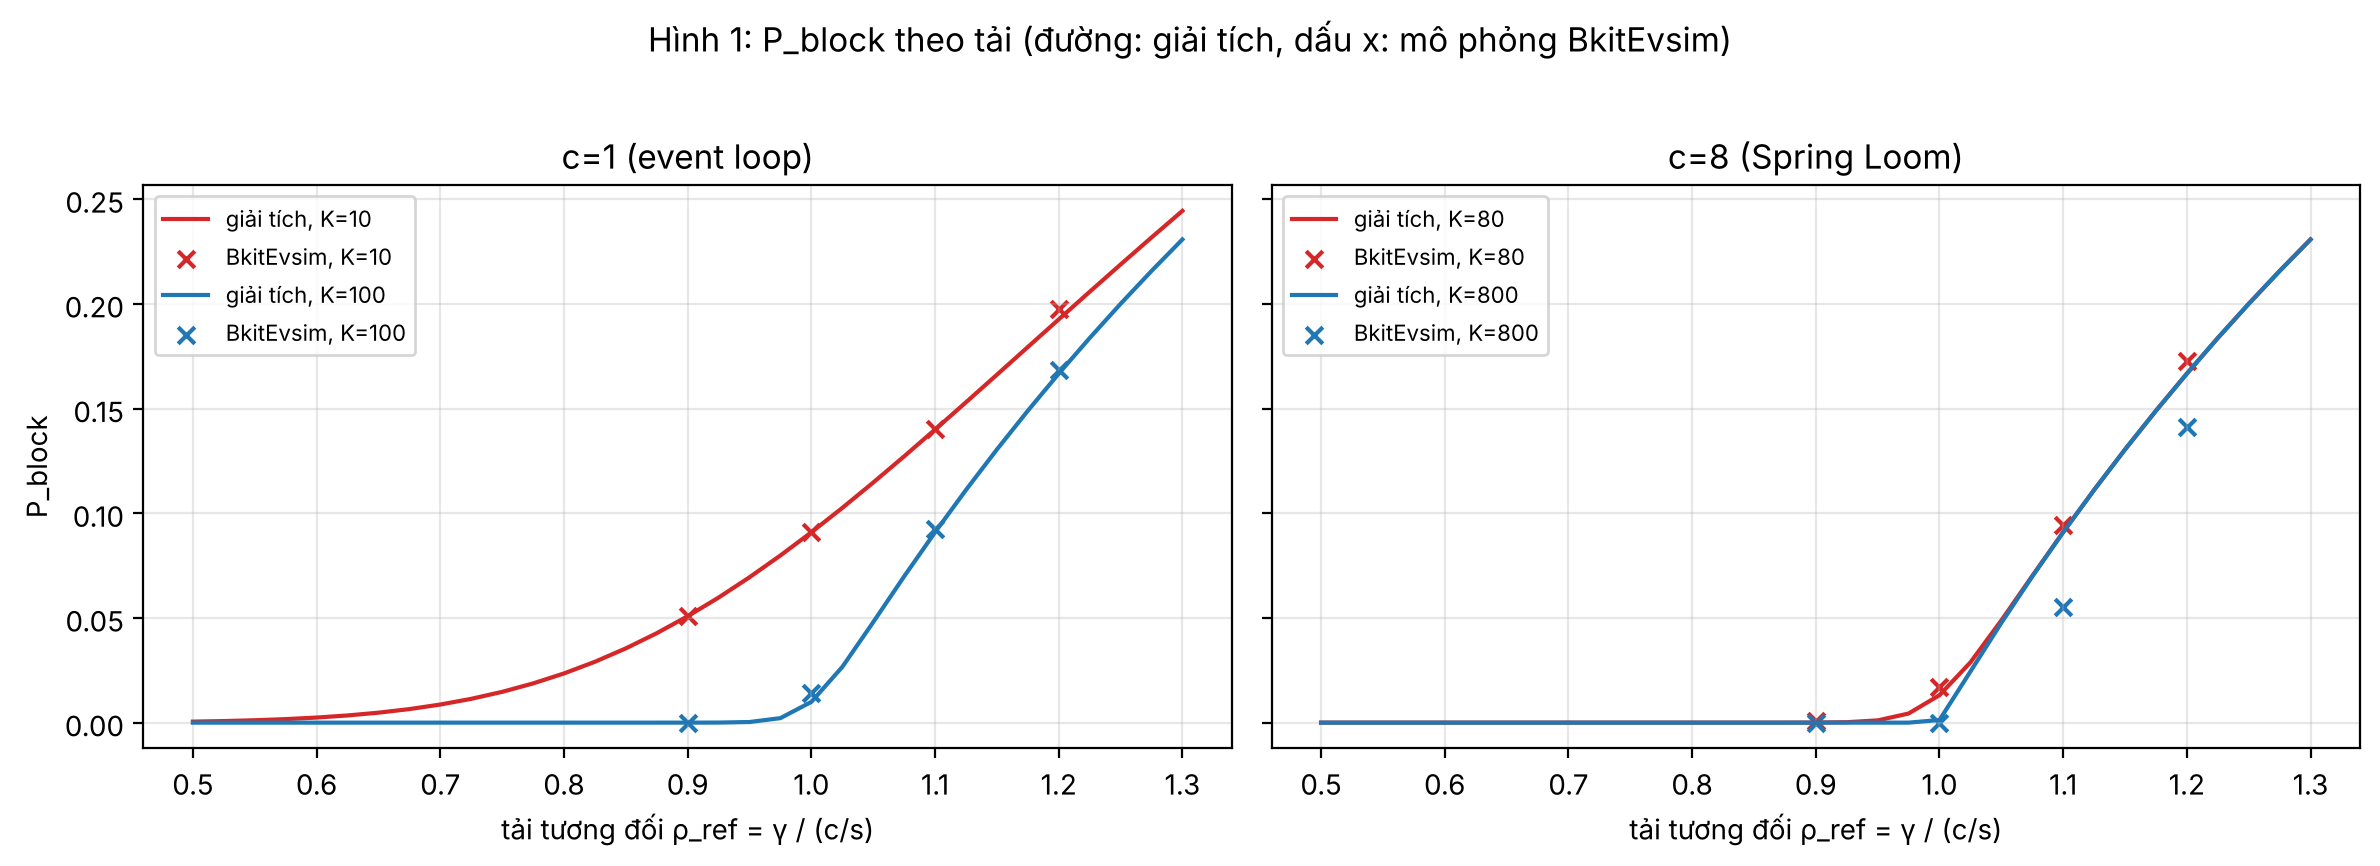

In [16]:
# Hình minh họa 1: P_block theo tải, giải tích so với mô phỏng BkitEvsim, thay K/core (c=1: event loop; c=8: Loom)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
rhos = np.linspace(0.5, 1.3, 33)
for ax, c_ in zip(axes, (1, 8)):
    for kpc, col in ((10, "tab:red"), (100, "tab:blue")):
        K_ = kpc * c_
        ax.plot(rhos, [tandem(r * c_ / s, c_, K_, s, D)["Pblock"] for r in rhos], color=col, label=f"giải tích, K={K_}")
        pts = [(r, run_model(r * c_ / s, c_, K_, s, D, n_req=20_000, seed=5)["Pblock"]) for r in (0.9, 1.0, 1.1, 1.2)]
        ax.scatter(*zip(*pts), color=col, marker="x", label=f"BkitEvsim, K={K_}")
    ax.set_title(f"c={c_}" + (" (event loop)" if c_ == 1 else " (Spring Loom)"))
    ax.set_xlabel("tải tương đối ρ_ref = γ / (c/s)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("P_block")
fig.suptitle("Hình 1: P_block theo tải (đường: giải tích, dấu x: mô phỏng BkitEvsim)", y=1.02)
plt.tight_layout(); plt.show()

## 8. Bước 8 – Thiết kế thí nghiệm (mô tả kế hoạch)

**Mục tiêu:** thu nhiều thông tin nhất với ít công sức nhất. Không chạy tổ hợp đầy đủ mọi factor mà chia thành sáu thí nghiệm, mỗi thí nghiệm trả lời một câu hỏi ở §1.2.

| # | Thí nghiệm | Factor đổi | Giữ cố định | Trả lời |
|---|---|---|---|---|
| E1 | Quét tải tới bão hòa | tải tuyệt đối `γ` ∈ {200; 400; 600; 800; 950; 1.100; 1.500; 3.000; 5.000; 7.500; 8.800} req/s, chung cho mọi hệ; hệ ∈ {Event loop, Loom} | `s`=1 ms, `D`=50 ms, `K` cơ sở | hệ nào bão hòa trước (câu 1, 2, 3) |
| E2 | Closed-loop (`C` kết nối) | `C` ∈ {100; 1.500; 5.000}; `K/core` ∈ {100; ∞} | `s`, `D`, `c`; `t_err` = 10 ms; `n_req` = max(30.000; 100·`C`) khi `K` hữu hạn | tỉ lệ lỗi, Little (câu 6) |
| E3 | Độ trễ I/O và thời gian CPU | `D` ∈ {10; 50; 200 ms} × `s` ∈ {0,2; 1; 5 ms}; hệ ∈ {Event loop, Loom} | `γ = 0,8/s` req/s (chung cho các hệ, bằng 0,8 × trần của hệ yếu nhất) | `R` tăng đúng `D`; CPU-bound hay I/O-bound (câu 5) |
| E4 | Số core và dung lượng | `c` ∈ {1; 4; 8} × `K/core` ∈ {10; 100; ∞} | `ρ_ref`=0,95 | ảnh hưởng của `c`, `K` lên `P_block` và `R` (câu 4) |
| E5 | Validation | node đơn (6 mô hình) × 3 mức tải; tandem CPU → I/O | – | mô phỏng so với giải tích (§9) |
| E6 | Giai thừa 2³ | `ρ_ref` {0,7; 1,1} × `K/core` {10; 100} × `c` {1; 8} | – | tương tác giữa các yếu tố |

**Quy trình mỗi lần chạy:** khởi tạo LP, chạy `n` request, **bỏ 10% đầu** (warm-up), ghi metric ở `SinkLP`, `DispatcherLP`, `WorkerLP`, `IoLP`; mỗi cấu hình chạy với **nhiều hạt giống ngẫu nhiên cố định để tái lập**; thứ tự chạy được ngẫu nhiên hóa.

Bun (nhiều kernel thread, mỗi thread một hàng) được thêm vào E1, E3 ở Phase 2, khi thành phần chia tải tới các hàng được cài đặt (§13); kỳ vọng giải tích là $8 \times$ M/M/1/K.


In [17]:
SEEDS, N_REQ = 10, 30_000
plan = []
GAMMAS_E1 = [200, 400, 600, 800, 950, 1100, 1500, 3000, 5000, 7500, 8800]   # req/s, chung cho mọi hệ (event loop bão hòa ở 1.000, Loom ở 8.000)
SYS2 = {"EventLoop": 1, "Loom": 8}                              # tên hệ: số core c
for name, c_ in SYS2.items():                                   # E1
    for g in GAMMAS_E1:
        plan.append(dict(exp="E1", system=name, c=c_, load="open", level=None, gamma=g, C=None, K_per_core=100, D=50e-3, s=1e-3))
for name, c_ in SYS2.items():                                   # E2
    for C_ in (100, 1500, 5000):
        for kpc in (100, None):
            plan.append(dict(exp="E2", system=name, c=c_, load="closed", level=None, C=C_, K_per_core=kpc, D=50e-3, s=1e-3))
for name, c_ in SYS2.items():                                   # E3
    for D_ in (10e-3, 50e-3, 200e-3):
        for s_ in (0.2e-3, 1e-3, 5e-3):
            plan.append(dict(exp="E3", system=name, c=c_, load="open", level=None, gamma=0.8 / s_, C=None, K_per_core=100, D=D_, s=s_))   # γ chung = 0,8 × trần của hệ yếu nhất (event loop: 1/s)
for c_ in (1, 4, 8):                                           # E4
    for kpc in (10, 100, None):
        plan.append(dict(exp="E4", system=f"c={c_}", c=c_, load="open", level=0.95, C=None, K_per_core=kpc, D=50e-3, s=1e-3))
for rho in (0.7, 1.1):                                         # E6 (2^3)
    for kpc in (10, 100):
        for c_ in (1, 8):
            plan.append(dict(exp="E6", system=f"c={c_}", c=c_, load="open", level=rho, C=None, K_per_core=kpc, D=50e-3, s=1e-3))
plan = pd.DataFrame(plan)

runs = plan.loc[plan.index.repeat(SEEDS)].copy()
runs["seed"] = runs.groupby(level=0).cumcount() + 1
runs = runs.reset_index(drop=True).sample(frac=1, random_state=2026).reset_index(drop=True)   # ngẫu nhiên hóa thứ tự
runs.insert(0, "run_id", range(1, len(runs) + 1))
runs["n_requests"] = N_REQ
runs["t_err"] = None
e2 = runs["exp"] == "E2"        # closed-loop: K hữu hạn thì phần lớn lần thử bị từ chối (t_err = 10 ms), cần n_req lớn để cửa sổ đo đủ dài
runs.loc[e2, "t_err"] = 1e-2
runs.loc[e2, "n_requests"] = [int(max(30_000, 100 * C_)) if pd.notna(k) else 30_000 for C_, k in zip(runs.loc[e2, "C"], runs.loc[e2, "K_per_core"])]

summary = plan.groupby("exp").size().rename("số cấu hình").to_frame()
summary.loc["E5 (validation, §9)"] = 18                       # 6 mô hình × 3 mức tải
summary["số lần chạy"] = summary["số cấu hình"] * SEEDS
summary.loc["Tổng"] = summary.sum()
print(summary.to_string())
runs.head(6)

                     số cấu hình  số lần chạy
exp                                          
E1                            22          220
E2                            12          120
E3                            18          180
E4                             9           90
E6                             8           80
E5 (validation, §9)           18          180
Tổng                          87          870


,run_id,exp,system,c,load,level,gamma,C,K_per_core,D,s,seed,n_requests,t_err
0,1,E1,Loom,8,open,NaN,8800.0,NaN,100.0,0.05,0.001,2,30000,None
1,2,E1,Loom,8,open,NaN,950.0,NaN,100.0,0.05,0.001,10,30000,None
2,3,E4,c=4,4,open,0.95,NaN,NaN,10.0,0.05,0.001,8,30000,None
3,4,E1,EventLoop,1,open,NaN,400.0,NaN,100.0,0.05,0.001,9,30000,None
4,5,E3,EventLoop,1,open,NaN,160.0,NaN,100.0,0.20,0.005,5,30000,None
5,6,E4,c=1,1,open,0.95,NaN,NaN,NaN,0.05,0.001,3,30000,None


In [18]:
# Ước lượng thời gian bằng cách đo một lần chạy BkitEvsim thật
t0 = time.time(); rr = run_model(7600, 8, 800, 1e-3, 50e-3, n_req=N_REQ, seed=1); dt = time.time() - t0
total = int(summary.loc["Tổng", "số lần chạy"])
print(f"1 lần chạy BkitEvsim ({N_REQ} request, {rr['events']} sự kiện): {dt:.1f} s  ({rr['events']/dt:,.0f} sự kiện/s)")
est = (runs["n_requests"].sum() + (total - len(runs)) * N_REQ) / N_REQ * dt     # tính theo số request; E2 có n_req lớn hơn
print(f"{total} lần chạy ≈ {est/60:.0f} phút ≈ {est/3600:.1f} giờ (cận trên, chạy tuần tự, một máy)")

1 lần chạy BkitEvsim (30000 request, 240001 sự kiện): 4.8 s  (49,736 sự kiện/s)
870 lần chạy ≈ 102 phút ≈ 1.7 giờ (cận trên, chạy tuần tự, một máy)


**Kiểm soát sai lệch:** bỏ warm-up; nhiều hạt giống; ngẫu nhiên hóa thứ tự; kiểm tra thứ tự pop của LadderQueue (§6.5); kiểm tra Little và bảo toàn request ở mọi lần chạy; loại lần chạy vi phạm; mọi thao tác chờ dùng thời gian mô phỏng, không dùng timeout theo đồng hồ thật.

### 8.1 Kế hoạch kiểm tra mô hình

**Verification (mô hình có được xây đúng không)**

| Nhóm | Kiểm tra | Cách làm | Tiêu chí |
|---|---|---|---|
| Component testing | Từng trạm độc lập | cắt riêng một trạm, cấp tải Poisson, so với công thức: M/M/1, M/M/c, M/M/1/K, M/M/c/K, M/M/∞, M/M/c/c; mỗi trạm thử ≥ 3 mức tải (thấp, cao, quá tải với trạm hữu hạn) | giá trị lý thuyết nằm trong khoảng tin cậy 95%; sai số tương đối < 5% |
| Component testing | Tandem CPU → I/O | so $R=W_{\mathrm{CPU}}+D$, $L_{\mathrm{IO}}=\lambda_{\mathrm{eff}}D$, `P_block` với công thức (§6.8) | sai số < 3% |
| Logical consistency | Định luật Little | kiểm tra `L_CPU = λ_eff·W_CPU`, `L_q = λ_eff·W_q` ở trạm CPU; `L_sys = X·R` toàn hệ thống | sai số < 3%, cùng nhóm request và cùng khoảng quan sát |
| Logical consistency | Bảo toàn request | $N_0+N_{\mathrm{arrived}}=N_{\mathrm{done}}+N_{\mathrm{rejected}}+N_{\mathrm{remaining}}$; số bị từ chối = số đến khi `n_CPU = K` | hai vế bằng nhau, không thiếu hay đếm trùng |
| Logical consistency | Bất biến | số server bận ≤ `c`; số request ở trạm CPU ≤ `K` tại mọi thời điểm | không vi phạm |
| Trace analysis | Thứ tự thời gian | timestamp sự kiện không giảm; local virtual time không giảm; số lần timestamp bị lùi khi pop | không vi phạm (số lần lùi = 0) |
| Trace analysis | Tái lập | cùng seed | kết quả giống hệt |
| Trace analysis | Hai dispatcher | `sequential` và `distributed_sequential` (cần xác nhận cả hai chạy được LP coroutine; nếu không thì so ở bản LP đồng bộ) | thống kê tương đương |
| Trace analysis | Độc lập với thời gian thực | chạy khi máy tải nặng/nhẹ; mọi độ trễ là sự kiện có timestamp mô phỏng | kết quả không đổi |

**Validation (mô hình có đúng với hệ thống thật không)**

| Nhóm | Kiểm tra | Cách làm | Tiêu chí |
|---|---|---|---|
| Model accuracy | Chỉ số cả hệ | so `X`, `P_block`, `R`, `U` đo được với công thức ở 4 workload và nêu sai lệch | đúng xu hướng; sai lệch được giải thích |
| System testing | Hành vi hợp lý | tăng `γ` thì `R` và `P_block` tăng; thêm server thì `R` giảm; tăng `D` thì `R` tăng đúng `D` | đúng chiều |
| Realistic scenarios | Hành vi hệ thống thực | event loop bão hòa ở `1/s`, Loom ở `c/s`; closed-loop quá tải tạo tỉ lệ lỗi cao | khớp định tính |
| Realistic scenarios | (Tùy chọn) Số liệu thực | tự chạy `wrk` một lần cho mỗi runtime | cùng bậc độ lớn |

## 9. Bước 9 – Phân tích số liệu (mô tả kế hoạch)

**Việc sẽ làm sau khi có số liệu:**
1. **Thống kê mô tả:** với mỗi cấu hình và metric, trung bình qua các hạt giống, độ lệch chuẩn, **khoảng tin cậy 95%** (phân phối t).
2. **Kiểm tra nhất quán:** Little ở mọi lần chạy; bảo toàn request; `ρ` đo được so với `λ_eff·s/c`.
3. **Validation:** sai số tương đối giữa mô phỏng và giải tích ở tải thấp và gần bão hòa.
4. **So sánh hệ thống:** kiểm định không tham số (Mann–Whitney) hoặc t-test Welch giữa hai hệ; báo cả kích thước hiệu ứng, không chỉ p-value.
5. **Điểm bão hòa (knee):** tải mà thông lượng ngừng tăng hoặc `R` tăng đột ngột; so với `X_max` lý thuyết.
6. **Xác định nút cổ chai:** nút nào có `U` cao nhất, `P_block` tăng sớm nhất.
7. **Độ nhạy và tương tác:** xếp hạng ảnh hưởng của các factor; phân tích phương sai cho thiết kế 2³ (E6).
8. **Giải thích sai lệch:** với mỗi chỗ mô phỏng lệch công thức (ví dụ hiệu ứng khởi động khi `K` lớn và quá tải, §7.5), nêu nguyên nhân và coi đó là giới hạn của cách đo chứ không phải lỗi mô hình.

In [19]:
def mean_ci(x, conf=0.95):
    x = np.asarray(x, dtype=float)
    n = len(x)
    m = x.mean()
    if n < 2:
        return m, np.nan, np.nan
    h = stats.sem(x) * stats.t.ppf((1 + conf) / 2, n - 1)
    return m, m - h, m + h

def compare_runs(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    sp = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return dict(mean_a=a.mean(), mean_b=b.mean(), ratio_a_over_b=a.mean() / b.mean(),
                p_value=u.pvalue, cohen_d=(a.mean() - b.mean()) / sp if sp > 0 else np.nan)

def validation_error(measured, predicted):
    measured, predicted = np.asarray(measured, float), np.asarray(predicted, float)
    return 100 * (measured - predicted) / predicted

def knee(loads, throughputs, tol=0.02):
    # Điểm bão hòa: tải đầu tiên mà thông lượng tăng thêm dưới tol so với bước trước
    for i in range(1, len(loads)):
        if throughputs[i] < throughputs[i - 1] * (1 + tol):
            return loads[i - 1]
    return loads[-1]

def little_check(L, X, R, tol=0.03):
    # Little ở một trạm hoặc toàn hệ thống: trả về (X·R, lệch tương đối, đạt?)
    dev = abs(L - X * R) / L
    return X * R, dev, dev <= tol

def conservation_check(n_start, n_arrived, n_done, n_blocked, n_remaining):
    # N_0 + N_arrived = N_done + N_rejected + N_remaining
    return (n_start + n_arrived) == (n_done + n_blocked + n_remaining)

def bottleneck(c, s):
    # Trần thông lượng chỉ do CPU (c/s); chờ I/O không chiếm CPU nên D không xuất hiện
    caps = {"CPU (c/s)": c / s}
    k = min(caps, key=caps.get)
    return k, caps[k], caps

# Thử hàm bằng DỮ LIỆU GIẢ (KHÔNG phải kết quả mô phỏng)
rng = np.random.default_rng(0)
demo = rng.normal(52.5, 0.4, size=10)
print("mean, ci_low, ci_high =", [round(float(v), 2) for v in mean_ci(demo)])
print("knee (giả):", knee([100, 200, 400, 800, 1000], [100, 200, 400, 790, 800]))
_x, _d, _ok = little_check(10.0, 200.0, 0.0505)
print("Little (giả): X·R =", round(float(_x), 3), "| lệch", round(float(_d), 3), "| đạt:", bool(_ok))
print("Bảo toàn (giả):", conservation_check(5, 1000, 950, 40, 15))
for nme, cfg in [("Event loop", (1, s)), ("Spring Loom", (8, s))]:
    k, v, _ = bottleneck(*cfg)
    print(f"  {nme:20s}: nghẽn ở {k:24s} X_max = {v:7.0f} req/s")

mean, ci_low, ci_high = [52.53, 52.31, 52.76]
knee (giả): 800
Little (giả): X·R = 10.1 | lệch 0.01 | đạt: True
Bảo toàn (giả): True
  Event loop          : nghẽn ở CPU (c/s)                X_max =    1000 req/s
  Spring Loom         : nghẽn ở CPU (c/s)                X_max =    8000 req/s


## 10. Bước 10 – Trình bày kết quả (mô tả kế hoạch)

**Báo cáo PDF (Phase 2) gồm:** báo cáo Phase 1 (notebook này), sơ đồ kiến trúc và sơ đồ lớp (các LP), mô tả workload, mô tả thí nghiệm, validation và đánh giá, hướng dẫn sử dụng; đóng gói `Spe-Ass-final-<GroupName>.zip` cùng file PDF.

**Biểu đồ và bảng dự kiến**

| # | Hình / bảng | Thí nghiệm | Mục đích |
|---|---|---|---|
| 1 | Thông lượng theo tải, mỗi hệ một đường, dải khoảng tin cậy | E1 | điểm bão hòa của từng hệ |
| 2 | Thời gian phản hồi (trung bình, p99) theo tải | E1 | đoạn tăng dốc gần bão hòa |
| 3 | `P_block` theo tải và `K` (mô phỏng so với giải tích) | E4, E5 | ảnh hưởng của `K`, độ chính xác mô phỏng |
| 4 | Bản đồ nhiệt `U` theo (hệ, tải) | E1, E3 | nút nào bận nhất |
| 5 | Thời gian phản hồi `R` theo độ trễ I/O `D` | E3 | `R` tăng đúng `D`; phần chênh giữa các đường là `W_CPU` |
| 6 | `P_block` theo `c` và `K` | E4 | ảnh hưởng giới hạn hàng chờ |
| 7 | `X·R` so với `C`, tỉ lệ lỗi theo `C` | E2 | Little và tỉ lệ lỗi closed-loop |
| 8 | Bảng đối chiếu mô phỏng và lý thuyết từng node | E5 | verification |

Hình dưới là **dự đoán giải tích với tham số giả định** (không phải kết quả mô phỏng), cho thấy dạng của hình 5.

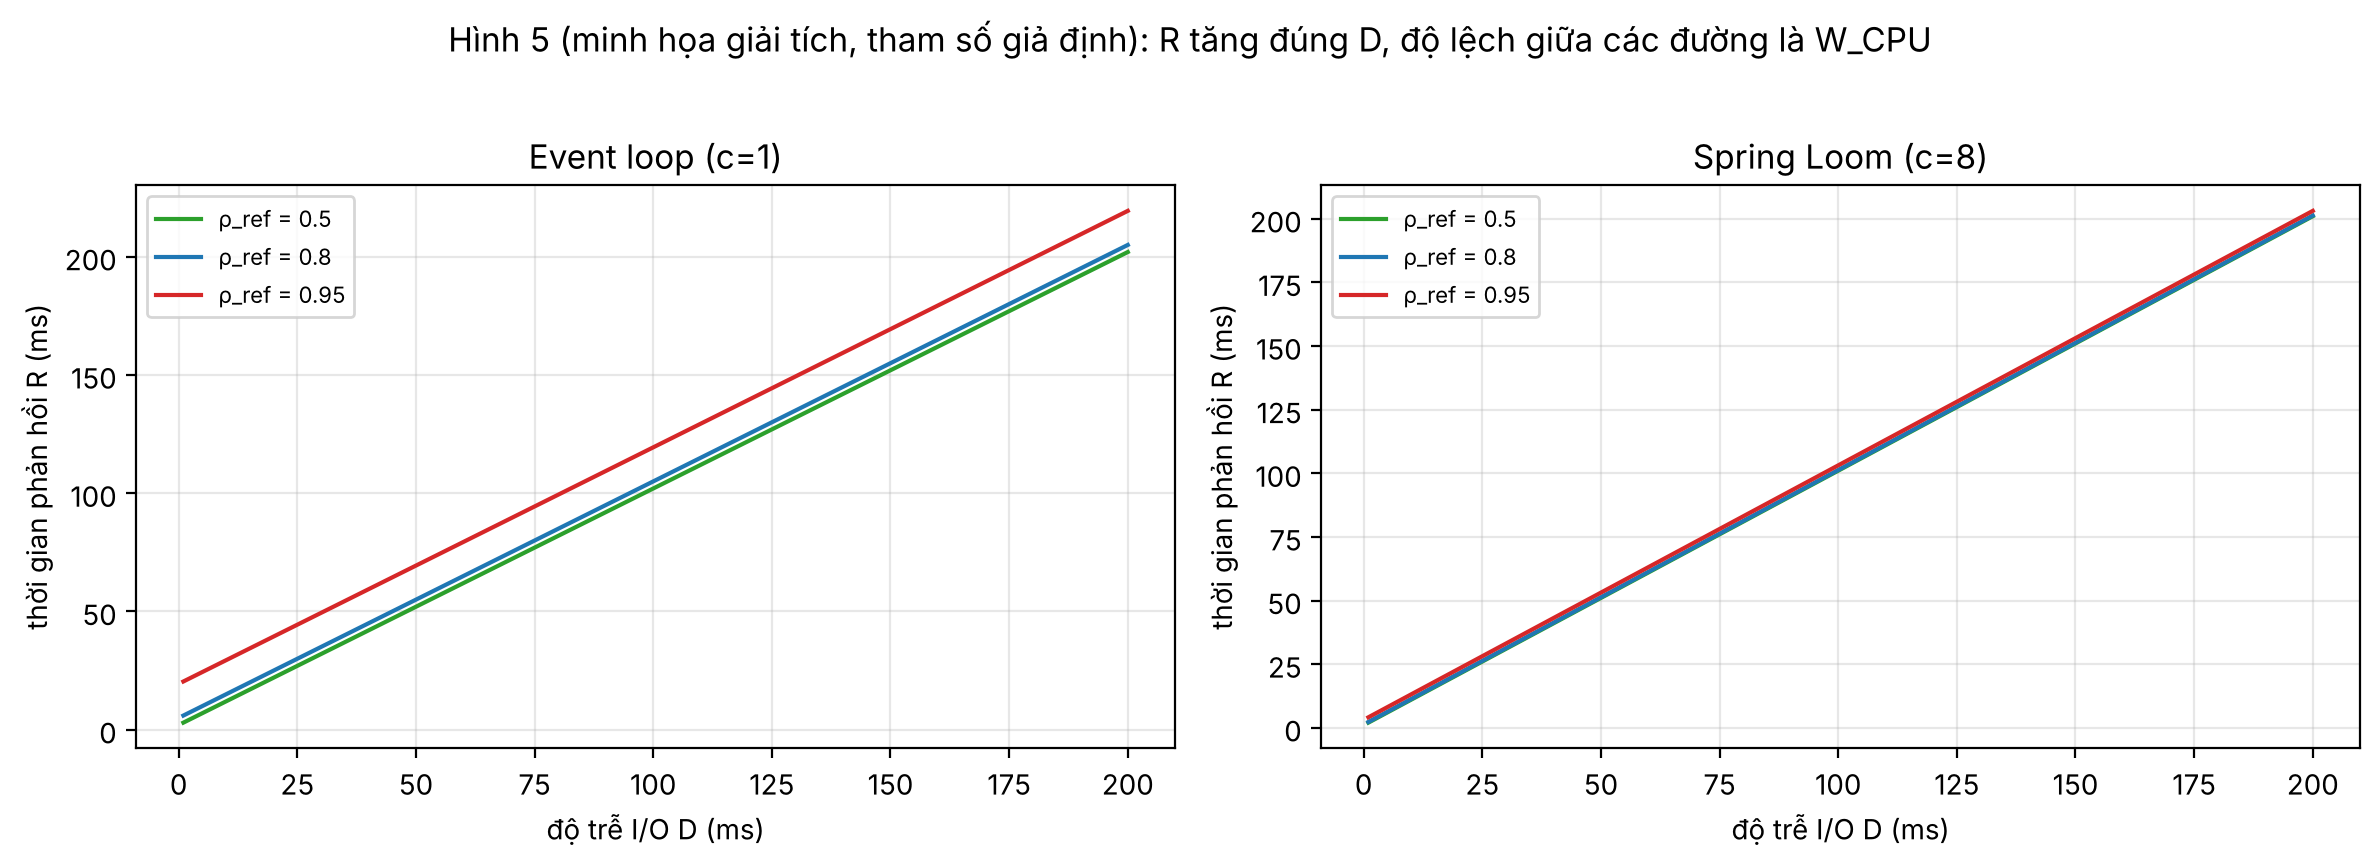

In [20]:
ds = np.linspace(0.001, 0.2, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (nm, c_, K_) in zip(axes, [("Event loop (c=1)", 1, 100), ("Spring Loom (c=8)", 8, 800)]):
    for rho, col in ((0.5, "tab:green"), (0.8, "tab:blue"), (0.95, "tab:red")):
        lam = rho * c_ / s
        ax.plot(ds * 1000, [tandem(lam, c_, K_, s, d)["R"] * 1000 for d in ds], color=col, label=f"ρ_ref = {rho}")
    ax.set_xlabel("độ trễ I/O D (ms)"); ax.set_ylabel("thời gian phản hồi R (ms)"); ax.set_title(nm)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.suptitle("Hình 5 (minh họa giải tích, tham số giả định): R tăng đúng D, độ lệch giữa các đường là W_CPU", y=1.02)
plt.tight_layout(); plt.show()

## 11. Mô tả module

### 11.1 Kiến trúc tổng thể

```
┌──────────────────────────── Configuration & Setup ────────────────────────────┐
│  Simulation Options: end_time, dispatcher, bucket_width, log_level, stats_file │
│  Tham số kịch bản: γ, c, K, s, D, κ, C, warm-up, m (số lần lặp)               │
└────────────────────────────────────────────────────────────────────────────────┘
┌──────── Application Layer (user model) ────────┐   ┌───────── Core (bkitevsim) ─────────┐
│ Logical Processes (mỗi LP = 1 thành phần):     │   │ Dispatcher: sequential |           │
│  SourceLP     – sinh request ~ Exp(γ) hoặc C   │◄─►│            distributed_sequential  │
│                 kết nối (closed-loop)          │   │ Event processing: pop →            │
│  DispatcherLP – hàng chờ FIFO, giới hạn K      │   │   set_local_virt_time →            │
│  WorkerLP × c – c server của trạm CPU          │   │   handle_event → send_event        │
│  IoLP         – trạm chờ I/O: M/M/∞ (độ trễ D) │   │ Priority queue: LadderQueue        │
│  SinkLP       – thu request, đo thời gian      │   │ BkSysCoEventLoop + BkSysFuture     │
│ Mỗi LP là một coroutine, trao đổi bằng sự kiện │   │   (coroutine + giờ mô phỏng)       │
└────────────────────────────────────────────────┘   └────────────────────────────────────┘
┌──────────────────────────── Infrastructure Services ──────────────────────────┐
│  State management: trạng thái LP, danh sách server rảnh, hàng chờ              │
│  Logging & stats collector: log sự kiện, thống kê, xuất CSV                    │
└────────────────────────────────────────────────────────────────────────────────┘
```

### 11.2 Đặc tả thành phần

- **SourceLP.** Open-loop: sinh request theo Poisson tốc độ `γ`, mỗi request có mã định danh và thời điểm đến. Closed-loop: giữ `C` kết nối, kết nối gửi request kế tiếp ngay khi nhận phản hồi (kể cả phản hồi bị từ chối).
- **DispatcherLP (hàng chờ của trạm CPU).** Nhận `REQ`: nếu số request trong trạm bằng `K` thì **từ chối** (gửi `REJECT` về Sink); ngược lại giao cho worker rảnh hoặc xếp vào hàng FIFO. Nhận `IDLE` từ worker: giảm bộ đếm, giao việc kế tiếp hoặc đánh dấu worker rảnh.
- **WorkerLP × c (server).** Nhận `JOB`, phục vụ `Exp(s)` (gửi sự kiện `SERVED` cho chính mình tại `now + Exp(s)`), rồi nhả ngay (gửi `IDLE` về Dispatcher) và chuyển request sang `IoLP`.
- **IoLP (trạm I/O).** Không giới hạn chỗ: với mỗi `IO_REQ`, lên lịch sự kiện `IO_FIN` cho chính nó tại `now + Exp(D)` rồi chuyển `DONE` đến Sink (không chờ từng request). Không phản hồi lên trạm CPU.
- **SinkLP.** Thu request hoàn thành và request bị từ chối, ghi thời gian phản hồi kèm lý do rời đi (`DONE`, `REJECTED`).
- **Cơ chế BkitEvsim.** Toàn bộ xử lý nằm trong `handle_event`; mọi độ trễ (CPU, I/O) là sự kiện gửi cho chính LP với timestamp ở tương lai, nên không dùng tham số `timeout` (theo đồng hồ thật) của `wait_for`. Thuật toán chi tiết ở §6.5, mã ở §6.6.

### 11.3 Luồng hoạt động

1. `SourceLP` sinh request tại thời điểm `t` và lên lịch lần đến kế tiếp sau `Exp(γ)` (open-loop).
2. Request đến `DispatcherLP`: nếu `n = K` thì bị từ chối (`REJECT` đến Sink); ngược lại giao cho worker rảnh hoặc xếp hàng.
3. `WorkerLP` phục vụ CPU `Exp(s)`, nhả server (`IDLE`) và chuyển request sang `IoLP`.
4. `IoLP` lên lịch `IO_FIN` tại `now + Exp(D)` rồi gửi `DONE` đến `SinkLP`.
5. `SinkLP` ghi thời gian phản hồi `R` (từ lúc đến đến lúc Sink nhận).
6. Mô phỏng dừng khi hết sự kiện hoặc tại `T_end`; thống kê chỉ tính sau thời gian khởi động.

### 11.4 Tổng kết

| Thành phần | Vai trò | Mô hình | Sự kiện chính |
|---|---|---|---|
| SourceLP | sinh request | Poisson(γ) / closed-loop | `REQ` |
| DispatcherLP | hàng chờ + giới hạn `K` | phần hàng chờ của M/M/c/K | `REQ`, `IDLE`, `JOB`, `REJECT` |
| WorkerLP × c | server CPU | phần phục vụ của M/M/c/K | `JOB`, `IO_REQ`, `IDLE` |
| IoLP | trạm chờ I/O | M/M/∞ | `IO_REQ`, `IO_DONE` |
| SinkLP | thu request, đo thời gian | bộ thu thống kê | `IO_DONE`, `DONE`, `REJECT` |



## 12. Checklist và việc còn mở

**Checklist Phase 1 (thiết kế)**
- [ ] Đăng link sample lên forum
- [x] Phân biệt hệ thực và mô phỏng (§0.2); phân loại các cách làm bất đồng bộ (§0.3)
- [x] Chạy các ví dụ asyncio minh họa của nhóm (§0.5)
- [x] Chạy các ví dụ asyncio của đề (Listing 1–3, §0.5)
- [x] Bước 1–7 đã có (§1–§7)
- [ ] Điền ô thông tin nhóm
- [x] Bước 8–10 đã mô tả kế hoạch (§8–§10) và mô tả module (§11)
- [ ] Xuất PDF `Spe-Ass-Spec-<GroupName>.pdf`

**Việc còn mở**
1. Bun là multi kernel thread: cần xác nhận cách phân việc cho các thread (hàng riêng hay hàng chung) để chọn $8 \times$ M/M/1/K hay M/M/N/K (§1.4, giả định 3).
2. Giá trị `κ` của kernel thread là giả thuyết; cần xác nhận hoặc đo.
3. Phần mô phỏng đã chạy ở §7.5, §6.7–§6.8 mới có event loop và Loom; Bun thêm ở Phase 2.
4. Giấy phép framework chỉ cho dùng trong môn học, không đăng mã công khai.

## 13. Kế hoạch Phase 2 (development)

| # | Việc | Kết quả |
|---|---|---|
| 1 | Chạy các ví dụ asyncio có sẵn trong đề và ví dụ ở §0.5; ghi lại output, đọc timeline | hiểu `await`, task, `gather`, future/callback, `StreamReader/StreamWriter`, `asyncio.run` |
| 2 | Lập bảng ánh xạ hệ thực sang mô hình DES (§0.3, §6.1), mỗi cách làm một dòng, ghi rõ giả định | bảng ánh xạ có giả định |
| 3 | Cài mô hình trên BkitEvsim: event loop, Loom (đã có khung, §6.6); thêm Bun (thành phần chia tải tới $N$ hàng, mỗi hàng một worker); thử `await`/`BkSysFuture` cho bước chờ I/O (§0.1) | `run_model` hỗ trợ cả ba cách làm |
| 4 | Kiểm chứng từng mô hình với công thức (§6.7–§6.8, E5) | sai số dưới 5% |
| 5 | Chạy thí nghiệm E1–E6 (§8), thêm S10 (request có CPU dài) | số liệu có khoảng tin cậy 95% |
| 6 | Phân tích hành vi (§9): event loop bị chặn bởi tác vụ CPU dài; kernel thread bị giới hạn bởi số thread; virtual thread mở rộng tốt khi tải nghiêng về I/O | giải thích điểm nghẽn |
| 7 | Gọi tên hàng đợi hình thành trong kết quả (M/M/1/K, M/M/c/K, M/M/∞) để giải thích hiện tượng, không dùng làm điểm xuất phát | phần giải thích trong báo cáo |
| 8 | (Tùy chọn) đối chiếu xu hướng với hệ thực: server nhỏ cùng workload trên asyncio, Bun, Spring Loom | so xu hướng, không so con số |
| 9 | Viết báo cáo, ghi rõ chỗ nào là hệ thực, chỗ nào là mô hình; đóng gói `Spe-Ass-final-<GroupName>.zip` | PDF + zip |